In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Database Connection & SQL Extraction**

In [2]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
import math


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.dummy import DummyClassifier

import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, f1_score, recall_score, confusion_matrix
from sklearn.model_selection import cross_val_score



In [3]:

warnings.filterwarnings('ignore')

# Connection to SQLite database
db_path = '/content/drive/MyDrive/ML_Assignment/database.sqlite'
conn = sqlite3.connect(db_path)
print("Database connected.")

# Find all tables
tables_query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""
tables = pd.read_sql(tables_query, conn)
display(tables)

# Extract match details
query = """
SELECT
    m.*,
    c.name AS country_name,
    l.name AS league_name,
    ht.team_fifa_api_id AS home_team_fifa_api_id,
    ht.team_long_name AS home_team_long_name,
    ht.team_short_name AS home_team_short_name,
    at.team_fifa_api_id AS away_team_fifa_api_id,
    at.team_long_name AS away_team_long_name,
    at.team_short_name AS away_team_short_name
FROM
    Match m
LEFT JOIN
    Country c ON m.country_id = c.id
LEFT JOIN
    League l ON m.league_id = l.id
LEFT JOIN
    Team ht ON m.home_team_api_id = ht.team_api_id
LEFT JOIN
    Team at ON m.away_team_api_id = at.team_api_id
ORDER BY
    m.date ASC;
"""
df_matches = pd.read_sql(query, conn)

#  Create Target Variable
def get_match_outcome(row):
    if row['home_team_goal'] > row['away_team_goal']:
        return 2
    elif row['home_team_goal'] == row['away_team_goal']:
        return 1
    else:
        return 0

df_matches['target'] = df_matches.apply(get_match_outcome, axis=1)

Database connected.


,name
0,Country
1,League
2,Match
3,Player
4,Player_Attributes
5,Team
6,Team_Attributes
7,sqlite_sequence


## **Member 1's Task (EDA & Data Quality)**

**1.Dataset Overview**

In [4]:
#Available Tables
table_names = tables['name'].tolist()

print("Available tables:")

for table in table_names:
    print("-", table)

Available tables:
- Country
- League
- Match
- Player
- Player_Attributes
- Team
- Team_Attributes
- sqlite_sequence


In [5]:
df_matches.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,BSA,country_name,league_name,home_team_fifa_api_id,home_team_long_name,home_team_short_name,away_team_fifa_api_id,away_team_long_name,away_team_short_name,target
0,24559,24558,24558,2008/2009,1,2008-07-18 00:00:00,486263,10192,9931,1,...,NaN,Switzerland,Switzerland Super League,900.0,BSC Young Boys,YB,896.0,FC Basel,BAS,0
1,24560,24558,24558,2008/2009,1,2008-07-19 00:00:00,486264,9930,10179,3,...,NaN,Switzerland,Switzerland Super League,434.0,FC Aarau,AAR,110770.0,FC Sion,SIO,2
2,24561,24558,24558,2008/2009,1,2008-07-20 00:00:00,486265,10199,9824,1,...,NaN,Switzerland,Switzerland Super League,897.0,FC Luzern,LUZ,286.0,FC Vaduz,VAD,0
3,24562,24558,24558,2008/2009,1,2008-07-20 00:00:00,486266,7955,10243,1,...,NaN,Switzerland,Switzerland Super League,435.0,Neuchâtel Xamax,XAM,894.0,FC Zürich,ZUR,0
4,24613,24558,24558,2008/2009,2,2008-07-23 00:00:00,486267,9931,9956,1,...,NaN,Switzerland,Switzerland Super League,896.0,FC Basel,BAS,322.0,Grasshopper Club Zürich,GRA,2


In [6]:
print("DATA TYPES ")

df_matches.info()

DATA TYPES 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25979 entries, 0 to 25978
Columns: 124 entries, id to target
dtypes: float64(98), int64(10), object(16)
memory usage: 24.6+ MB


In [7]:
#data type summary
dtype_summary = pd.DataFrame({
    'Column': df_matches.columns,
    'Data Type': df_matches.dtypes.astype(str),
    'Non-Null Count': df_matches.notna().sum().values,
    'Missing Count': df_matches.isna().sum().values,
    'Missing %': (df_matches.isna().mean() * 100).round(2).values,
    'Unique Values': df_matches.nunique().values
})

display(dtype_summary)

,Column,Data Type,Non-Null Count,Missing Count,Missing %,Unique Values
id,id,int64,25979,0,0.00,25979
country_id,country_id,int64,25979,0,0.00,11
league_id,league_id,int64,25979,0,0.00,11
season,season,object,25979,0,0.00,8
stage,stage,int64,25979,0,0.00,38
...,...,...,...,...,...,...
home_team_short_name,home_team_short_name,object,25979,0,0.00,259
away_team_fifa_api_id,away_team_fifa_api_id,float64,25801,178,0.69,285
away_team_long_name,away_team_long_name,object,25979,0,0.00,296
away_team_short_name,away_team_short_name,object,25979,0,0.00,259


In [8]:
data_dictionary = pd.DataFrame({
    'Variable': df_matches.columns,
    'Data Type': df_matches.dtypes.astype(str),
    'Unique Values': df_matches.nunique().values,
    'Missing Values': df_matches.isna().sum().values,
    'Missing %': (df_matches.isna().mean() * 100).round(2).values
})

display(data_dictionary)

,Variable,Data Type,Unique Values,Missing Values,Missing %
id,id,int64,25979,0,0.00
country_id,country_id,int64,11,0,0.00
league_id,league_id,int64,11,0,0.00
season,season,object,8,0,0.00
stage,stage,int64,38,0,0.00
...,...,...,...,...,...
home_team_short_name,home_team_short_name,object,259,0,0.00
away_team_fifa_api_id,away_team_fifa_api_id,float64,285,178,0.69
away_team_long_name,away_team_long_name,object,296,0,0.00
away_team_short_name,away_team_short_name,object,259,0,0.00


In [9]:
#numerical and categorical
print(" NUMERICAL VARIABLES ")

numeric_cols = df_matches.select_dtypes(
    include=np.number
).columns.tolist()

print(numeric_cols)

print("\n CATEGORICAL VARIABLES")

categorical_cols = df_matches.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print(categorical_cols)

 NUMERICAL VARIABLES 
['id', 'country_id', 'league_id', 'stage', 'match_api_id', 'home_team_api_id', 'away_team_api_id', 'home_team_goal', 'away_team_goal', 'home_player_X1', 'home_player_X2', 'home_player_X3', 'home_player_X4', 'home_player_X5', 'home_player_X6', 'home_player_X7', 'home_player_X8', 'home_player_X9', 'home_player_X10', 'home_player_X11', 'away_player_X1', 'away_player_X2', 'away_player_X3', 'away_player_X4', 'away_player_X5', 'away_player_X6', 'away_player_X7', 'away_player_X8', 'away_player_X9', 'away_player_X10', 'away_player_X11', 'home_player_Y1', 'home_player_Y2', 'home_player_Y3', 'home_player_Y4', 'home_player_Y5', 'home_player_Y6', 'home_player_Y7', 'home_player_Y8', 'home_player_Y9', 'home_player_Y10', 'home_player_Y11', 'away_player_Y1', 'away_player_Y2', 'away_player_Y3', 'away_player_Y4', 'away_player_Y5', 'away_player_Y6', 'away_player_Y7', 'away_player_Y8', 'away_player_Y9', 'away_player_Y10', 'away_player_Y11', 'home_player_1', 'home_player_2', 'home_pla

In [10]:
#check structure
for table in table_names:

    print("TABLE:", table)

    df_temp = pd.read_sql(
        f'SELECT * FROM "{table}" LIMIT 5',
        conn
    )

    print("Rows displayed:", len(df_temp))
    print("Columns:", df_temp.columns.tolist())

    display(df_temp)

TABLE: Country
Rows displayed: 5
Columns: ['id', 'name']


,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy


TABLE: League
Rows displayed: 5
Columns: ['id', 'country_id', 'name']


,id,country_id,name
0,1,1,Belgium Jupiler League
1,1729,1729,England Premier League
2,4769,4769,France Ligue 1
3,7809,7809,Germany 1. Bundesliga
4,10257,10257,Italy Serie A


TABLE: Match
Rows displayed: 5
Columns: ['id', 'country_id', 'league_id', 'season', 'stage', 'date', 'match_api_id', 'home_team_api_id', 'away_team_api_id', 'home_team_goal', 'away_team_goal', 'home_player_X1', 'home_player_X2', 'home_player_X3', 'home_player_X4', 'home_player_X5', 'home_player_X6', 'home_player_X7', 'home_player_X8', 'home_player_X9', 'home_player_X10', 'home_player_X11', 'away_player_X1', 'away_player_X2', 'away_player_X3', 'away_player_X4', 'away_player_X5', 'away_player_X6', 'away_player_X7', 'away_player_X8', 'away_player_X9', 'away_player_X10', 'away_player_X11', 'home_player_Y1', 'home_player_Y2', 'home_player_Y3', 'home_player_Y4', 'home_player_Y5', 'home_player_Y6', 'home_player_Y7', 'home_player_Y8', 'home_player_Y9', 'home_player_Y10', 'home_player_Y11', 'away_player_Y1', 'away_player_Y2', 'away_player_Y3', 'away_player_Y4', 'away_player_Y5', 'away_player_Y6', 'away_player_Y7', 'away_player_Y8', 'away_player_Y9', 'away_player_Y10', 'away_player_Y11', 'home_p

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


... (6 outputs left out)

TABLE: Team_Attributes
Rows displayed: 5
Columns: ['id', 'team_fifa_api_id', 'team_api_id', 'date', 'buildUpPlaySpeed', 'buildUpPlaySpeedClass', 'buildUpPlayDribbling', 'buildUpPlayDribblingClass', 'buildUpPlayPassing', 'buildUpPlayPassingClass', 'buildUpPlayPositioningClass', 'chanceCreationPassing', 'chanceCreationPassingClass', 'chanceCreationCrossing', 'chanceCreationCrossingClass', 'chanceCreationShooting', 'chanceCreationShootingClass', 'chanceCreationPositioningClass', 'defencePressure', 'defencePressureClass', 'defenceAggression', 'defenceAggressionClass', 'defenceTeamWidth', 'defenceTeamWidthClass', 'defenceDefenderLineClass']


,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


TABLE: sqlite_sequence
Rows displayed: 5
Columns: ['name', 'seq']


,name,seq
0,Team,103916
1,Country,51958
2,League,51958
3,Match,51958
4,Player,11075


**2.Data Quality Assessment**

In [11]:
# Convert the date column to datetime objects
date_series = pd.to_datetime(df_matches['date'])

print('Missing dates:', date_series.isna().sum())
print('Start:', date_series.min().strftime('%Y-%m-%d'))
print('End:', date_series.max().strftime('%Y-%m-%d'))

Missing dates: 0
Start: 2008-07-18
End: 2016-05-25


In [12]:
# Missing values
missing = df_matches.isnull().sum()

display(missing[missing > 0])

,0
home_player_X1,1821
home_player_X2,1821
home_player_X3,1832
home_player_X4,1832
home_player_X5,1832
...,...
BSH,11818
BSD,11818
BSA,11818
home_team_fifa_api_id,178


In [13]:
missing_summary = pd.DataFrame({
    'Missing Count': df_matches.isnull().sum(),
    'Missing Percentage': (
        df_matches.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    'Missing Percentage',
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
PSH,14811,57.01
PSD,14811,57.01
PSA,14811,57.01
GBH,11817,45.49
BSH,11818,45.49
...,...,...
league_name,0,0.00
home_team_short_name,0,0.00
away_team_long_name,0,0.00
away_team_short_name,0,0.00


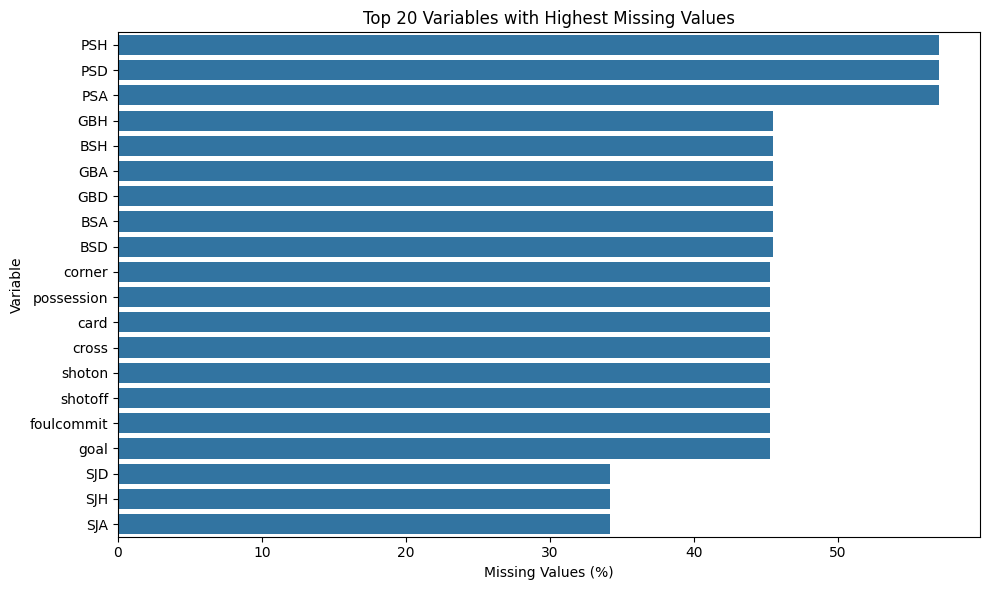

In [14]:
# Show the 20 columns with the most missing values.

missing_plot = missing_summary[
    missing_summary['Missing Count'] > 0
].sort_values(
    'Missing Percentage',
    ascending=False
).head(20)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=missing_plot['Missing Percentage'],
    y=missing_plot.index
)

plt.xlabel('Missing Values (%)')
plt.ylabel('Variable')
plt.title('Top 20 Variables with Highest Missing Values')

plt.tight_layout()
plt.show()

In [15]:
# Check whether missing Bet365 odds depend on the league.
odds_columns = ['B365H', 'B365D', 'B365A']

missing_odds_by_league = (
    df_matches.assign(
        missing_odds=df_matches[
            odds_columns
        ].isna().any(axis=1)
    )
    .groupby('league_name')
    .agg(
        Total_Matches=('match_api_id', 'size'),
        Missing_Odds=('missing_odds', 'sum')
    )
)

missing_odds_by_league['Missing %'] = (
    missing_odds_by_league['Missing_Odds']
    / missing_odds_by_league['Total_Matches']
    * 100
).round(2)

display(missing_odds_by_league)

,Total_Matches,Missing_Odds,Missing %
league_name,,,
Belgium Jupiler League,1728,22,1.27
England Premier League,3040,0,0.00
France Ligue 1,3040,4,0.13
Germany 1. Bundesliga,2448,1,0.04
Italy Serie A,3017,6,0.20
Netherlands Eredivisie,2448,3,0.12
Poland Ekstraklasa,1920,1920,100.00
Portugal Liga ZON Sagres,2052,8,0.39
Scotland Premier League,1824,0,0.00


In [16]:
# Show how many matches would be lost when incomplete odds are removed.
complete_odds = df_matches[
    odds_columns
].notna().all(axis=1)

print("Total matches:", len(df_matches))

print(
    "Matches with complete Bet365 odds:",
    complete_odds.sum()
)

print(
    "Matches lost if missing odds are removed:",
    (~complete_odds).sum()
)

print(
    "Leagues remaining:",
    df_matches.loc[
        complete_odds, 'league_name'
    ].nunique()
)

Total matches: 25979
Matches with complete Bet365 odds: 22592
Matches lost if missing odds are removed: 3387
Leagues remaining: 9


In [17]:
# Duplicates check
duplicate_count = df_matches.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [18]:
# Check that available Bet365 odds are numbers greater than one.
odds_columns = ['B365H', 'B365D', 'B365A']
raw_odds = df_matches[odds_columns]
numeric_odds = raw_odds.apply(pd.to_numeric, errors='coerce')
odds_quality = pd.DataFrame({
    'Missing': raw_odds.isna().sum(),
    'Not numeric': (raw_odds.notna() & numeric_odds.isna()).sum(),
    'Not finite': (numeric_odds.notna() & ~np.isfinite(numeric_odds)).sum(),
    'At or below 1': numeric_odds.le(1).sum()
})
display(odds_quality)
if odds_quality[['Not numeric', 'Not finite', 'At or below 1']].to_numpy().sum() > 0:
    raise ValueError('Investigate invalid odds before continuing.')
df_matches[odds_columns] = numeric_odds

,Missing,Not numeric,Not finite,At or below 1
B365H,3387,0,0,0
B365D,3387,0,0,0
B365A,3387,0,0,0


In [19]:
#Anomaly check
print("Minimum home goals:",
      df_matches['home_team_goal'].min())

print("Minimum away goals:",
      df_matches['away_team_goal'].min())

print("Maximum home goals:",
      df_matches['home_team_goal'].max())

print("Maximum away goals:",
      df_matches['away_team_goal'].max())

Minimum home goals: 0
Minimum away goals: 0
Maximum home goals: 10
Maximum away goals: 9


In [20]:
max_home = df_matches['home_team_goal'].max()
max_away = df_matches['away_team_goal'].max()

print("Max home goals:", max_home)
display(df_matches[df_matches['home_team_goal'] == max_home])

print("Max away goals:", max_away)
display(df_matches[df_matches['away_team_goal'] == max_away])

Max home goals: 10


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,BSA,country_name,league_name,home_team_fifa_api_id,home_team_long_name,home_team_short_name,away_team_fifa_api_id,away_team_long_name,away_team_short_name,target
7405,13899,13274,13274,2010/2011,10,2010-10-24 00:00:00,836306,8640,10235,10,...,8.0,Netherlands,Netherlands Eredivisie,247.0,PSV,PSV,246.0,Feyenoord,FEY,2
24291,24248,21518,21518,2015/2016,16,2015-12-20 00:00:00,2030233,8633,8370,10,...,NaN,Spain,Spain LIGA BBVA,243.0,Real Madrid CF,REA,480.0,Rayo Vallecano,RAY,2


Max away goals: 9


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,BSA,country_name,league_name,home_team_fifa_api_id,home_team_long_name,home_team_short_name,away_team_fifa_api_id,away_team_long_name,away_team_short_name,target
25253,7661,4769,4769,2015/2016,30,2016-03-13 00:00:00,1990022,10242,9847,0,...,NaN,France,France Ligue 1,294.0,ES Troyes AC,TRO,73.0,Paris Saint-Germain,PSG,0


In [21]:
#check invalid scores
negative_goals = df_matches[
    (df_matches['home_team_goal'] < 0) |
    (df_matches['away_team_goal'] < 0)
]

print("Matches with negative goals:",
      len(negative_goals))

Matches with negative goals: 0


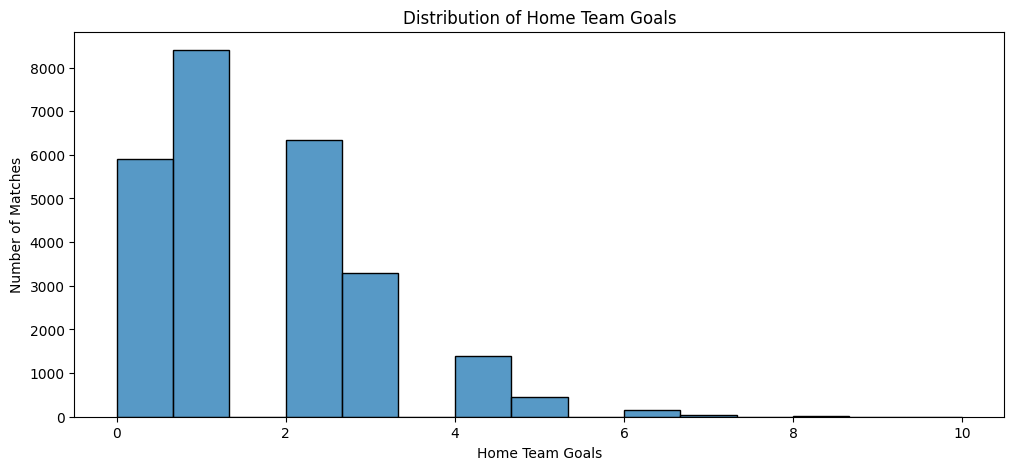

In [22]:
# Home team goals
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_matches,
    x='home_team_goal',
    bins=15,
)

plt.title('Distribution of Home Team Goals')
plt.xlabel('Home Team Goals')
plt.ylabel('Number of Matches')
plt.show()

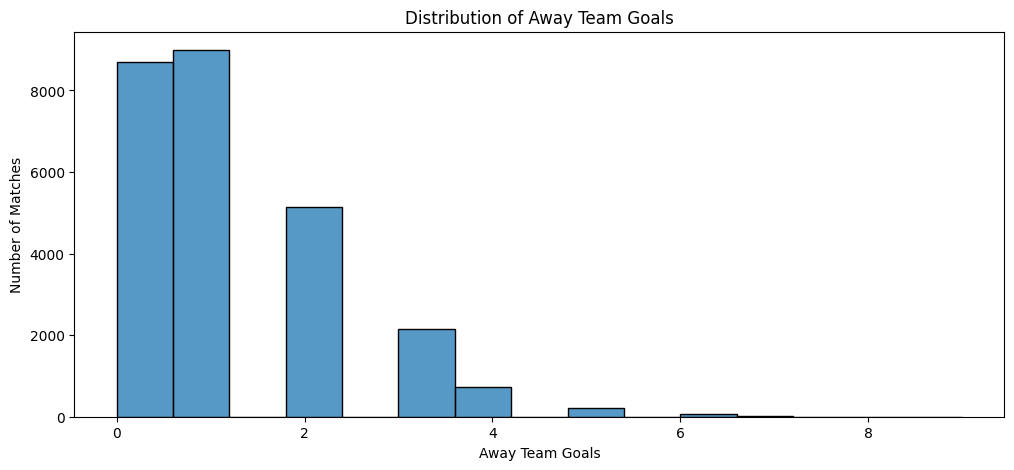

In [23]:
# away team goals
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_matches,
    x='away_team_goal',
    bins=15,
)

plt.title('Distribution of Away Team Goals')
plt.xlabel('Away Team Goals')
plt.ylabel('Number of Matches')
plt.show()

**3.Target Variable Analysis**


2 = Home Win

1 = Draw

0 = Away Win

In [24]:
target_labels = {
    0: 'Away Win',
    1: 'Draw',
    2: 'Home Win'
}

df_matches['target_label'] = df_matches['target'].map(target_labels)

target_counts = df_matches['target_label'].value_counts()

target_percentages = (
    df_matches['target_label']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages
})

display(target_summary)

,Count,Percentage
target_label,,
Home Win,11917,45.87
Away Win,7466,28.74
Draw,6596,25.39


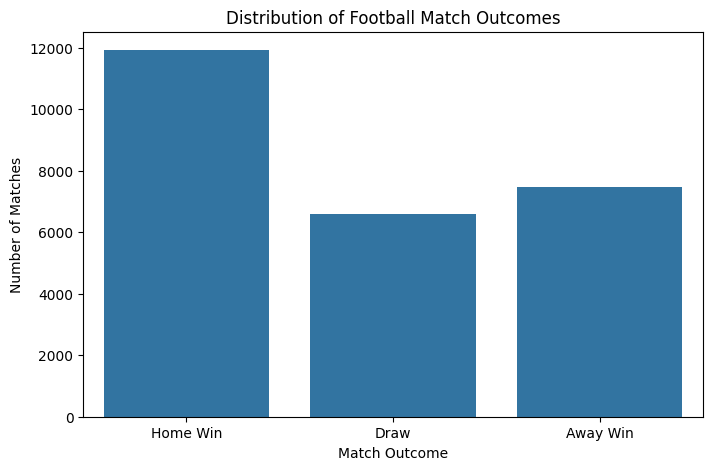

In [25]:
#target distribution chart
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_matches,
    x='target_label',
    order=['Home Win', 'Draw', 'Away Win']
)

plt.title('Distribution of Football Match Outcomes')
plt.xlabel('Match Outcome')
plt.ylabel('Number of Matches')
plt.show()

In [26]:

# Class imbalance -> the majority-class baseline

majority_class = target_counts.idxmax()
baseline_accuracy = target_counts.max() / len(df_matches) * 100

print("Majority class            :", majority_class)
print("Majority-class baseline   : {:.2f}% accuracy".format(baseline_accuracy))
print()
print("Imbalance ratio (largest : smallest class) = {:.2f} : 1".format(
    target_counts.max() / target_counts.min()))

Majority class            : Home Win
Majority-class baseline   : 45.87% accuracy

Imbalance ratio (largest : smallest class) = 1.81 : 1


In [27]:
#target distribution by sessions
season_outcome = pd.crosstab(
    df_matches['season'],
    df_matches['target_label'],
    normalize='index'
) * 100

season_outcome = season_outcome[
    ['Home Win', 'Draw', 'Away Win']
]

display(season_outcome.round(2))

target_label,Home Win,Draw,Away Win
season,,,
2008/2009,47.08,24.98,27.93
2009/2010,47.43,25.20,27.37
2010/2011,46.63,25.74,27.64
2011/2012,46.52,25.40,28.07
2012/2013,44.29,26.17,29.54
2013/2014,46.31,24.27,29.42
2014/2015,44.93,25.56,29.50
2015/2016,43.87,25.71,30.43


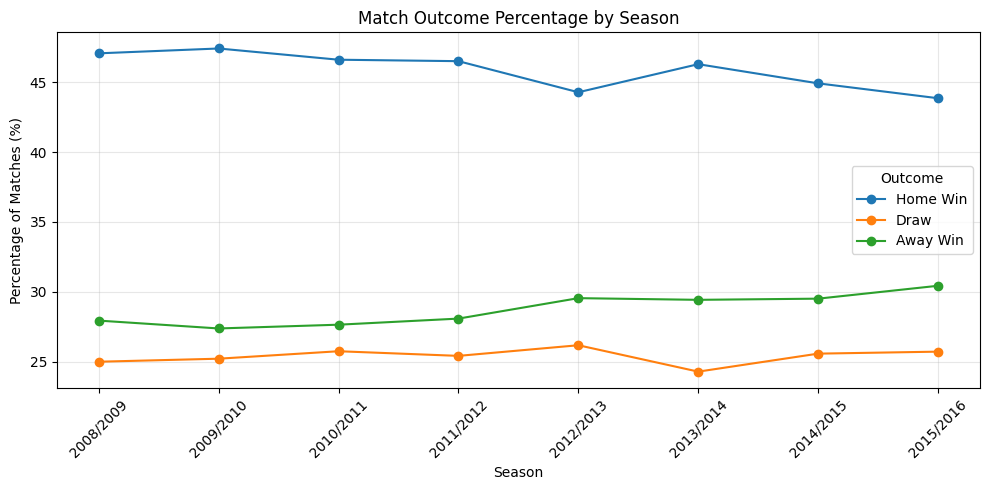

Home Win % in first season : 47.083583884546
Home Win % in last season  : 43.86650631389056
Change over the period     : -3.22 percentage points


In [28]:
# Is home advantage stable over time?

season_outcome.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Match Outcome Percentage by Season')
plt.xlabel('Season')
plt.ylabel('Percentage of Matches (%)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend(title='Outcome')
plt.tight_layout()
plt.show()

print("Home Win % in first season :", season_outcome['Home Win'].iloc[0])
print("Home Win % in last season  :", season_outcome['Home Win'].iloc[-1])
print("Change over the period     : {:.2f} percentage points".format(
    season_outcome['Home Win'].iloc[-1] - season_outcome['Home Win'].iloc[0]))

In [29]:
#target Distribution by league
league_outcome = pd.crosstab(
    df_matches['league_name'],
    df_matches['target_label'],
    normalize='index'
) * 100

league_outcome = league_outcome[
    ['Home Win', 'Draw', 'Away Win']
]

display(league_outcome.round(2))

target_label,Home Win,Draw,Away Win
league_name,,,
Belgium Jupiler League,46.88,24.59,28.53
England Premier League,45.72,25.76,28.52
France Ligue 1,44.70,28.26,27.04
Germany 1. Bundesliga,45.22,24.39,30.39
Italy Serie A,46.64,26.38,26.98
Netherlands Eredivisie,47.83,23.73,28.43
Poland Ekstraklasa,45.31,27.34,27.34
Portugal Liga ZON Sagres,44.25,25.97,29.78
Scotland Premier League,41.67,24.51,33.83


**4.Univariate Analysis**

In [30]:
# Descriptive statistics.

analysis_cols = [c for c in ['home_team_goal', 'away_team_goal', 'stage',
                             'B365H', 'B365D', 'B365A']
                 if c in df_matches.columns]

numeric_summary = df_matches[analysis_cols].describe().T
numeric_summary = numeric_summary.rename(columns={'50%': 'median'})

display(numeric_summary.round(3))

,count,mean,std,min,25%,median,75%,max
home_team_goal,25979.0,1.545,1.297,0.00,1.00,1.0,2.00,10.0
away_team_goal,25979.0,1.161,1.142,0.00,0.00,1.0,2.00,9.0
stage,25979.0,18.243,10.407,1.00,9.00,18.0,27.00,38.0
B365H,22592.0,2.629,1.794,1.04,1.67,2.1,2.80,26.0
B365D,22592.0,3.840,1.118,1.40,3.30,3.5,4.00,17.0
B365A,22592.0,4.662,3.730,1.08,2.50,3.5,5.25,51.0


In [31]:
goal_summary = df_matches[
    ['home_team_goal', 'away_team_goal']
].describe().T

goal_summary['median'] = df_matches[
    ['home_team_goal', 'away_team_goal']
].median()

display(goal_summary)

,count,mean,std,min,25%,50%,75%,max,median
home_team_goal,25979.0,1.544594,1.297158,0.0,1.0,1.0,2.0,10.0,1.0
away_team_goal,25979.0,1.160938,1.142110,0.0,0.0,1.0,2.0,9.0,1.0


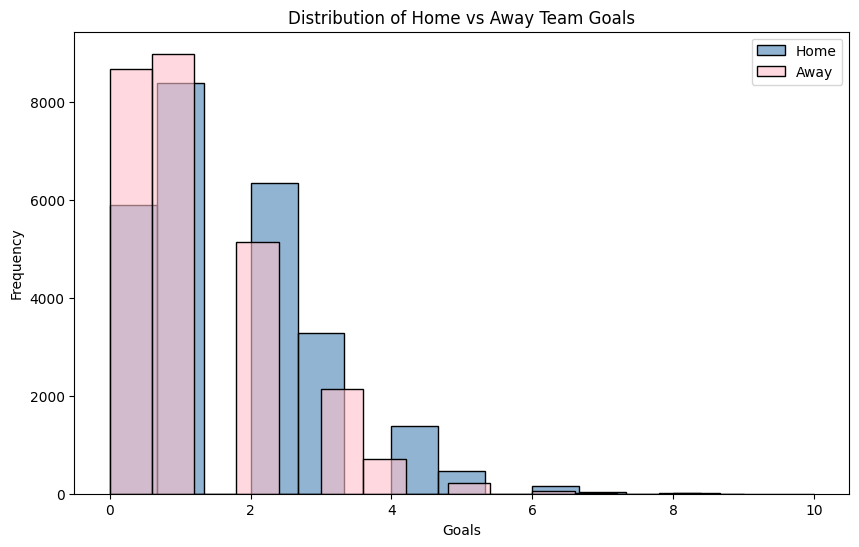

In [32]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df_matches, x='home_team_goal', bins=15,
             color='steelblue', label='Home', alpha=0.6)
sns.histplot(data=df_matches, x='away_team_goal', bins=15,
             color='pink', label='Away', alpha=0.6)

plt.title('Distribution of Home vs Away Team Goals')
plt.xlabel('Goals')
plt.ylabel('Frequency')
plt.legend()
plt.show()

**Boxplot-Outlier Analysis**

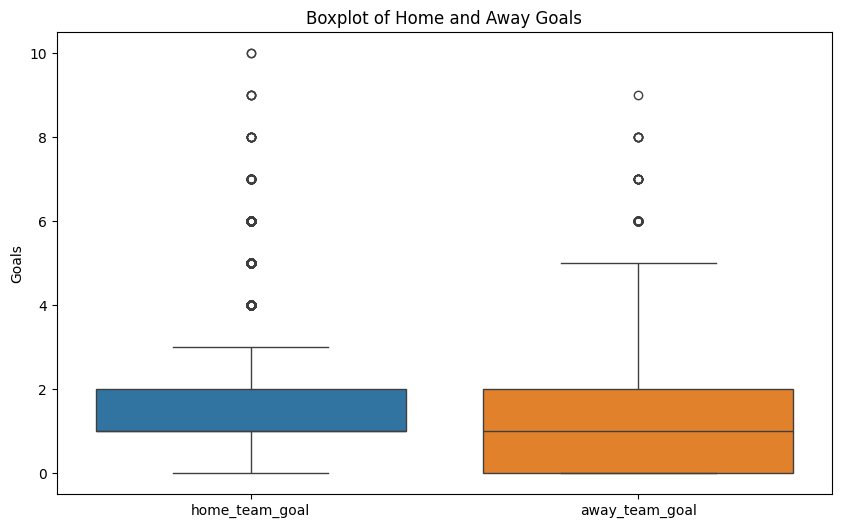

In [33]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_matches[
        ['home_team_goal', 'away_team_goal']
    ]
)

plt.title('Boxplot of Home and Away Goals')
plt.ylabel('Goals')
plt.show()

In [34]:
# Count scores outside the usual IQR limits.

def outlier_summary(data, columns):
    q1 = data[columns].quantile(0.25)
    q3 = data[columns].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((data[columns] < lower) | (data[columns] > upper)).sum()
    pct = (count / len(data) * 100).round(2)

    return pd.DataFrame({
        'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'Lower Bound': lower, 'Upper Bound': upper,
        'Outlier Count': count, 'Outlier %': pct
    })

goal_outliers = outlier_summary(df_matches, ['home_team_goal', 'away_team_goal'])
display(goal_outliers)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
home_team_goal,1.0,2.0,1.0,-0.5,3.5,2056,7.91
away_team_goal,0.0,2.0,2.0,-3.0,5.0,79,0.30


**Bivariate Analysis**

In [35]:
# Compare bookmaker coverage before explaining the selected odds.
bookmakers = [
    'B365', 'BW', 'IW', 'LB', 'PS',
    'WH', 'SJ', 'VC', 'GB', 'BS'
]

coverage = []

for bookmaker in bookmakers:

    columns = [
        f'{bookmaker}{suffix}'
        for suffix in 'HDA'
    ]

    if all(
        column in df_matches.columns
        for column in columns
    ):

        sub = df_matches[columns]

        coverage.append({
            'Bookmaker': bookmaker,

            'Missing %': round(
                sub.isna().mean().mean() * 100,
                2
            ),

            'Usable rows': int(
                sub.notna().all(axis=1).sum()
            )
        })

display(
    pd.DataFrame(coverage).sort_values('Missing %')
)

,Bookmaker,Missing %,Usable rows
0,B365,13.04,22592
1,BW,13.10,22575
5,WH,13.12,22571
7,VC,13.13,22568
3,LB,13.18,22556
2,IW,13.31,22520
6,SJ,34.19,17097
8,GB,45.49,14162
9,BS,45.49,14161
4,PS,57.01,11168


,B365H,B365D,B365A
target_label,,,
Home Win,2.075,4.080,5.958
Draw,2.599,3.615,4.046
Away Win,3.537,3.655,3.139


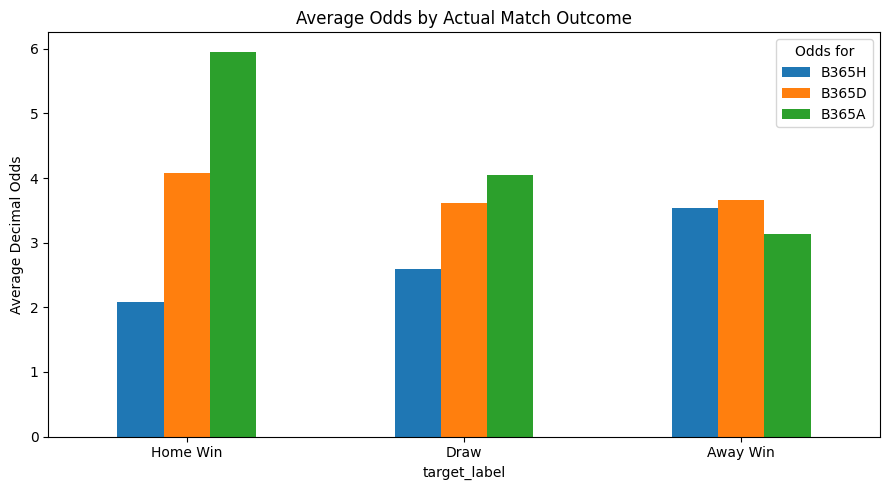

In [36]:
# Compare average Bet365 odds between actual outcome groups.
odds_cols = [
    column
    for column in ['B365H', 'B365D', 'B365A']
    if column in df_matches.columns
]

odds_by_outcome = (
    df_matches
    .groupby('target_label')[odds_cols]
    .mean()
    .round(3)
    .reindex(['Home Win', 'Draw', 'Away Win'])
)

display(odds_by_outcome)

odds_by_outcome.plot(
    kind='bar',
    figsize=(9, 5),
    rot=0,
    title='Average Odds by Actual Match Outcome',
    ylabel='Average Decimal Odds'
)

plt.legend(title='Odds for')
plt.tight_layout()
plt.show()

Home Advanatage Analysis

In [37]:

df_matches['goal_difference'] = (
    df_matches['home_team_goal'] -
    df_matches['away_team_goal']
)

In [38]:
print("Average home goals:",
      df_matches['home_team_goal'].mean())

print("Average away goals:",
      df_matches['away_team_goal'].mean())

print("Average goal difference:",
      df_matches['goal_difference'].mean())

Average home goals: 1.5445937103044767
Average away goals: 1.1609376804341969
Average goal difference: 0.38365602987027986


Multivariate Analysis

In [39]:
# Compare bookmaker coverage before explaining the selected odds.

bookmakers = ['B365', 'BW', 'IW', 'LB', 'PS', 'WH', 'SJ', 'VC', 'GB', 'BS']

coverage = []
for b in bookmakers:
    cols = [f'{b}{s}' for s in 'HDA']
    if all(c in df_matches.columns for c in cols):
        sub = df_matches[cols]
        coverage.append({
            'Bookmaker': b,
            'Missing %': round(sub.isna().mean().mean() * 100, 2),
            'Usable rows': int(sub.notna().all(axis=1).sum())
        })

display(pd.DataFrame(coverage).sort_values('Missing %'))

,Bookmaker,Missing %,Usable rows
0,B365,13.04,22592
1,BW,13.10,22575
5,WH,13.12,22571
7,VC,13.13,22568
3,LB,13.18,22556
2,IW,13.31,22520
6,SJ,34.19,17097
8,GB,45.49,14162
9,BS,45.49,14161
4,PS,57.01,11168


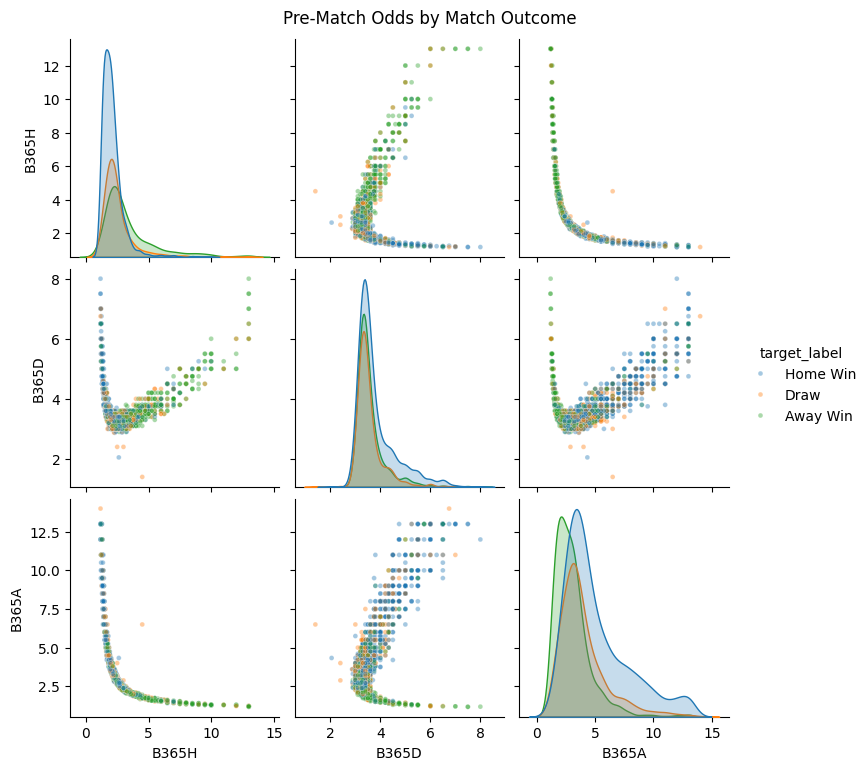

In [40]:
# Pairplot of pre-match odds, coloured by actual outcome (sampled for speed)
cols = ['B365H', 'B365D', 'B365A']
plot_data = df_matches[cols + ['target_label']].dropna()
plot_data = plot_data[(plot_data[cols] < 15).all(axis=1)]

sns.pairplot(
    plot_data.sample(n=min(3000, len(plot_data)), random_state=42),
    hue='target_label',
    hue_order=['Home Win', 'Draw', 'Away Win'],
    plot_kws={'alpha': 0.4, 's': 12}
)
plt.suptitle('Pre-Match Odds by Match Outcome', y=1.02)
plt.show()

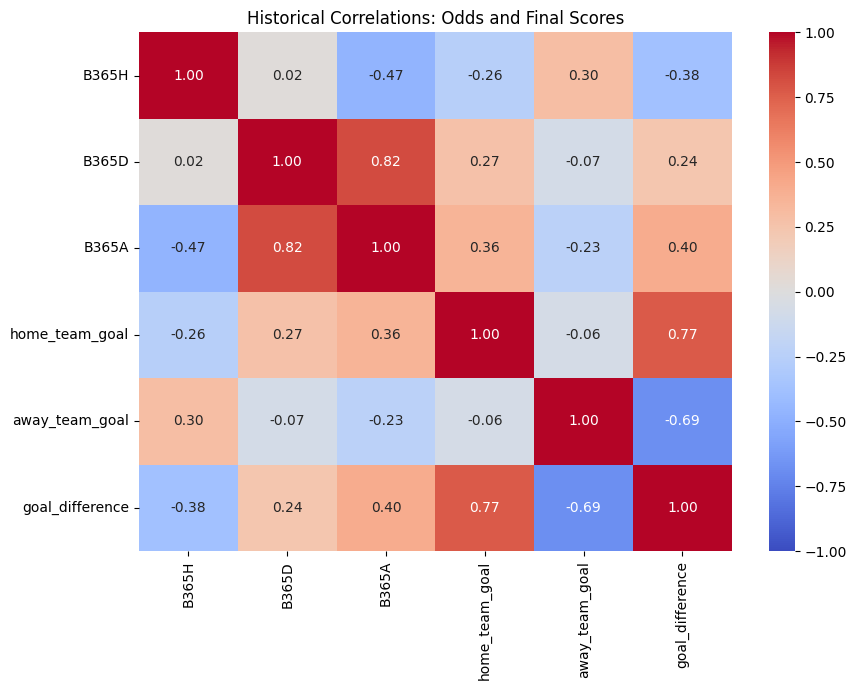

In [41]:

# Compare betting odds with final scores for historical analysis.
heatmap_cols = [
    'B365H',
    'B365D',
    'B365A',
    'home_team_goal',
    'away_team_goal',
    'goal_difference'
]

corr_matrix = df_matches[heatmap_cols].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Historical Correlations: Odds and Final Scores')
plt.tight_layout()
plt.show()



 Leakage checks and insight log

In [42]:
# List columns that must stay outside the pre-match predictors.
post_match_columns = ['home_team_goal', 'away_team_goal', 'goal_difference',
                      'goal', 'shoton', 'shotoff', 'foulcommit', 'card',
                      'cross', 'corner', 'possession']
leakage_rows = [
    {'Variable': column, 'Reason': 'Same-match information is known after kickoff'}
    for column in post_match_columns if column in df_matches.columns
]
leakage_rows += [
    {'Variable': 'target', 'Reason': 'This is the answer the model predicts'},
    {'Variable': 'target_label', 'Reason': 'This is the answer written as a label'}
]
display(pd.DataFrame(leakage_rows))

,Variable,Reason
0,home_team_goal,Same-match information is known after kickoff
1,away_team_goal,Same-match information is known after kickoff
2,goal_difference,Same-match information is known after kickoff
3,goal,Same-match information is known after kickoff
4,shoton,Same-match information is known after kickoff
5,shotoff,Same-match information is known after kickoff
6,foulcommit,Same-match information is known after kickoff
7,card,Same-match information is known after kickoff
8,cross,Same-match information is known after kickoff
9,corner,Same-match information is known after kickoff


In [43]:
# Calculate the missing variables to resolve NameError
league_season_counts = pd.crosstab(df_matches['league_name'], df_matches['season'])

# Find team names that have multiple team API IDs
team_counts = df_matches.groupby('home_team_long_name')['home_team_api_id'].nunique()
ambiguous_names = team_counts[team_counts > 1].index.tolist()

# Record findings using the values calculated above.
no_odds_leagues = missing_odds_by_league.index[
    missing_odds_by_league['Missing_Odds'] == missing_odds_by_league['Total_Matches']
].tolist()
smallest_coverage = league_season_counts.stack().idxmin()
insights = [
    ['Outcome balance', f'{majority_class}: {baseline_accuracy:.2f}%',
     'Evaluate all three classes and compare against a trained dummy baseline.'],
    ['Missing odds', ', '.join(no_odds_leagues) or 'No league has all odds missing',
     'Report leagues excluded when incomplete odds are removed.'],
    ['Smallest league-season coverage',
     f'{smallest_coverage}: {league_season_counts.loc[smallest_coverage[0], smallest_coverage[1]]} matches',
     'Investigate uneven coverage using the full match dataset.'],
    ['Extreme scores',
     f"Home maximum: {df_matches['home_team_goal'].max()}; away maximum: {df_matches['away_team_goal'].max()}",
     'Investigate high scores; do not delete them only because they are unusual.'],
    ['Team identity', f'{len(ambiguous_names)} names linked to multiple team IDs',
     'Use team IDs to group history.'],
    ['Seasonal variation',
     f"Home-win share changes by {season_outcome['Home Win'].iloc[-1] - season_outcome['Home Win'].iloc[0]:.2f} percentage points from first to last season",
     'Use chronological evaluation; this change alone is not a significance test.'],
    ['Predictor redundancy', 'Form goal difference = form scored - form conceded',
     'Review redundant predictors with Member 2.'],
    ['Leakage', 'Final scores define the target',
     'Keep same-match scores, events and target labels out of X.']
]
eda_insight_log = pd.DataFrame(insights, columns=['Finding', 'Evidence', 'Meaning / Action'])
display(eda_insight_log)

,Finding,Evidence,Meaning / Action
0,Outcome balance,Home Win: 45.87%,Evaluate all three classes and compare against...
1,Missing odds,"Poland Ekstraklasa, Switzerland Super League",Report leagues excluded when incomplete odds a...
2,Smallest league-season coverage,"('Belgium Jupiler League', '2013/2014'): 12 ma...",Investigate uneven coverage using the full mat...
3,Extreme scores,Home maximum: 10; away maximum: 9,Investigate high scores; do not delete them on...
4,Team identity,3 names linked to multiple team IDs,Use team IDs to group history.
5,Seasonal variation,Home-win share changes by -3.22 percentage poi...,Use chronological evaluation; this change alon...
6,Predictor redundancy,Form goal difference = form scored - form conc...,Review redundant predictors with Member 2.
7,Leakage,Final scores define the target,"Keep same-match scores, events and target labe..."


**Member 2's Task (Preprocessing & Feature
Engineering)**

**Step 1: Data Selection & Cleaning**

Removing unnecessary columns and those that could lead to data leakage.

In [44]:

# Data Selection & Cleaning
# Selecting necessary columns including pre-match bookmaker odds (B365H, B365D, B365A).
columns_to_keep = [
    'id', 'date', 'league_name', 'home_team_long_name', 'away_team_long_name',
    'home_team_goal', 'away_team_goal', 'target',
    'B365H', 'B365D', 'B365A'
]

available_cols = [col for col in columns_to_keep if col in df_matches.columns]
df_clean = df_matches[available_cols].copy()

df_clean.rename(columns={
    'home_team_long_name': 'home_team',
    'away_team_long_name': 'away_team'
}, inplace=True)

print("Step 1 Complete - Cleaned data shape:", df_clean.shape)
display(df_clean.head())

Step 1 Complete - Cleaned data shape: (25979, 11)


,id,date,league_name,home_team,away_team,home_team_goal,away_team_goal,target,B365H,B365D,B365A
0,24559,2008-07-18 00:00:00,Switzerland Super League,BSC Young Boys,FC Basel,1,2,0,NaN,NaN,NaN
1,24560,2008-07-19 00:00:00,Switzerland Super League,FC Aarau,FC Sion,3,1,2,NaN,NaN,NaN
2,24561,2008-07-20 00:00:00,Switzerland Super League,FC Luzern,FC Vaduz,1,2,0,NaN,NaN,NaN
3,24562,2008-07-20 00:00:00,Switzerland Super League,Neuchâtel Xamax,FC Zürich,1,2,0,NaN,NaN,NaN
4,24613,2008-07-23 00:00:00,Switzerland Super League,FC Basel,Grasshopper Club Zürich,1,0,2,NaN,NaN,NaN


In [45]:
#convert date
df_matches['date'] = pd.to_datetime(
    df_matches['date'],
    errors='coerce'
)


print("\nDate range:")
print("Start:", df_matches['date'].min())
print("End:", df_matches['date'].max())


Date range:
Start: 2008-07-18 00:00:00
End: 2016-05-25 00:00:00


In [46]:
# Viewing the first 5 rows
print(df_clean.head())

      id                 date               league_name        home_team  \
0  24559  2008-07-18 00:00:00  Switzerland Super League   BSC Young Boys   
1  24560  2008-07-19 00:00:00  Switzerland Super League         FC Aarau   
2  24561  2008-07-20 00:00:00  Switzerland Super League        FC Luzern   
3  24562  2008-07-20 00:00:00  Switzerland Super League  Neuchâtel Xamax   
4  24613  2008-07-23 00:00:00  Switzerland Super League         FC Basel   

                 away_team  home_team_goal  away_team_goal  target  B365H  \
0                 FC Basel               1               2       0    NaN   
1                  FC Sion               3               1       2    NaN   
2                 FC Vaduz               1               2       0    NaN   
3                FC Zürich               1               2       0    NaN   
4  Grasshopper Club Zürich               1               0       2    NaN   

   B365D  B365A  
0    NaN    NaN  
1    NaN    NaN  
2    NaN    NaN  
3    NaN

In [47]:
#Data leakage check

post_match_variables = [
    col for col in df_matches.columns
    if any(keyword in col.lower() for keyword in [
        'goal',
        'shot',
        'corner',
        'foul',
        'card',
        'possession',
        'cross'
    ])
]

print("Potential post-match variables:")
for col in post_match_variables:
    print("-", col)

Potential post-match variables:
- home_team_goal
- away_team_goal
- goal
- shoton
- shotoff
- foulcommit
- card
- cross
- corner
- possession
- goal_difference


In [48]:
leakage_check = pd.DataFrame({
    'Variable': post_match_variables,
    'Potential Leakage': 'Yes',
    'Reason': 'Match event/statistic may only be known during or after the match'
})

display(leakage_check)

,Variable,Potential Leakage,Reason
0,home_team_goal,Yes,Match event/statistic may only be known during...
1,away_team_goal,Yes,Match event/statistic may only be known during...
2,goal,Yes,Match event/statistic may only be known during...
3,shoton,Yes,Match event/statistic may only be known during...
4,shotoff,Yes,Match event/statistic may only be known during...
5,foulcommit,Yes,Match event/statistic may only be known during...
6,card,Yes,Match event/statistic may only be known during...
7,cross,Yes,Match event/statistic may only be known during...
8,corner,Yes,Match event/statistic may only be known during...
9,possession,Yes,Match event/statistic may only be known during...


**Step 2: Feature Engineering (Rolling Form & Goal Difference)**

In [49]:
# Sorting by date chronologically
df_clean['date'] = pd.to_datetime(df_clean['date'])
df_clean = df_clean.sort_values('date')

df_clean.head()

,id,date,league_name,home_team,away_team,home_team_goal,away_team_goal,target,B365H,B365D,B365A
0,24559,2008-07-18,Switzerland Super League,BSC Young Boys,FC Basel,1,2,0,NaN,NaN,NaN
1,24560,2008-07-19,Switzerland Super League,FC Aarau,FC Sion,3,1,2,NaN,NaN,NaN
2,24561,2008-07-20,Switzerland Super League,FC Luzern,FC Vaduz,1,2,0,NaN,NaN,NaN
3,24562,2008-07-20,Switzerland Super League,Neuchâtel Xamax,FC Zürich,1,2,0,NaN,NaN,NaN
4,24613,2008-07-23,Switzerland Super League,FC Basel,Grasshopper Club Zürich,1,0,2,NaN,NaN,NaN


In [50]:
# Separating data into groups for team-level history tracking
home_df = df_clean[['date', 'home_team', 'home_team_goal', 'away_team_goal']].copy().rename(
    columns={'home_team': 'team', 'home_team_goal': 'goals_scored', 'away_team_goal': 'goals_conceded'}
)
away_df = df_clean[['date', 'away_team', 'away_team_goal', 'home_team_goal']].copy().rename(
    columns={'away_team': 'team', 'away_team_goal': 'goals_scored', 'home_team_goal': 'goals_conceded'}
)
home_df.head()


,date,team,goals_scored,goals_conceded
0,2008-07-18,BSC Young Boys,1,2
1,2008-07-19,FC Aarau,3,1
2,2008-07-20,FC Luzern,1,2
3,2008-07-20,Neuchâtel Xamax,1,2
4,2008-07-23,FC Basel,1,0


In [51]:
# Combining into a single team history log
team_history = pd.concat([home_df, away_df]).sort_values(['team', 'date'])
team_history.head()

,date,team,goals_scored,goals_conceded
6709,2010-08-21,1. FC Kaiserslautern,3,1
6756,2010-08-27,1. FC Kaiserslautern,2,0
6912,2010-09-12,1. FC Kaiserslautern,1,2
6969,2010-09-18,1. FC Kaiserslautern,2,2
7043,2010-09-22,1. FC Kaiserslautern,0,5


In [52]:
# Rolling Form Calculation (Goals Scored, Goals Conceded, and Goal Difference)
team_history['rolling_goals_scored'] = team_history.groupby('team')['goals_scored'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
team_history['rolling_goals_conceded'] = team_history.groupby('team')['goals_conceded'].transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())

team_history.head()

,date,team,goals_scored,goals_conceded,rolling_goals_scored,rolling_goals_conceded
6709,2010-08-21,1. FC Kaiserslautern,3,1,NaN,NaN
6756,2010-08-27,1. FC Kaiserslautern,2,0,3.0,1.00
6912,2010-09-12,1. FC Kaiserslautern,1,2,2.5,0.50
6969,2010-09-18,1. FC Kaiserslautern,2,2,2.0,1.00
7043,2010-09-22,1. FC Kaiserslautern,0,5,2.0,1.25


In [53]:
# Added Goal Difference feature for stronger team strength representation
team_history['rolling_goal_diff'] = team_history['rolling_goals_scored'] - team_history['rolling_goals_conceded']

# Merging rolling features back to the main dataset for home team
df_features = pd.merge(
    df_clean,
    team_history[['date', 'team', 'rolling_goals_scored', 'rolling_goals_conceded', 'rolling_goal_diff']],
    left_on=['date', 'home_team'], right_on=['date', 'team'], how='left'
).rename(columns={
    'rolling_goals_scored': 'home_form_scored',
    'rolling_goals_conceded': 'home_form_conceded',
    'rolling_goal_diff': 'home_form_goal_diff'
}).drop('team', axis=1)

# Merging rolling features back to the main dataset for away team
df_features = pd.merge(
    df_features,
    team_history[['date', 'team', 'rolling_goals_scored', 'rolling_goals_conceded', 'rolling_goal_diff']],
    left_on=['date', 'away_team'], right_on=['date', 'team'], how='left'
).rename(columns={
    'rolling_goals_scored': 'away_form_scored',
    'rolling_goals_conceded': 'away_form_conceded',
    'rolling_goal_diff': 'away_form_goal_diff'
}).drop('team', axis=1)

# Ensure the 'id' column from df_matches is carried over
if 'id' not in df_features.columns and 'id' in df_clean.columns:
    df_features['id'] = df_clean['id']

# Cleaning initial matches where rolling metrics or odds might be missing
subset_cols = ['home_form_scored', 'away_form_scored']
if 'B365H' in df_features.columns:
    subset_cols.extend(['B365H', 'B365D', 'B365A'])

df_features.dropna(subset=subset_cols, inplace=True)
print("Step 2 Complete - Features added (including Goal Diff & Odds). New shape:", df_features.shape)
print("Columns in df_features:", df_features.columns.tolist())

Step 2 Complete - Features added (including Goal Diff & Odds). New shape: (22415, 17)
Columns in df_features: ['id', 'date', 'league_name', 'home_team', 'away_team', 'home_team_goal', 'away_team_goal', 'target', 'B365H', 'B365D', 'B365A', 'home_form_scored', 'home_form_conceded', 'home_form_goal_diff', 'away_form_scored', 'away_form_conceded', 'away_form_goal_diff']


**Step 3: Categorical Encoding**

Separation of Features and Target

In [54]:
# Selecting feature columns and target variable
feature_cols = [
    'league_name', 'home_team', 'away_team',
    'home_form_scored', 'home_form_conceded', 'home_form_goal_diff',
    'away_form_scored', 'away_form_conceded', 'away_form_goal_diff'
]

if 'B365H' in df_features.columns:
    feature_cols.extend(['B365H', 'B365D', 'B365A'])

X = df_features[feature_cols].copy()
y = df_features['target']
# Viewing data selected for X
X.head()

,league_name,home_team,away_team,home_form_scored,home_form_conceded,home_form_goal_diff,away_form_scored,away_form_conceded,away_form_goal_diff,B365H,B365D,B365A
53,France Ligue 1,Toulouse FC,Le Havre AC,0.0,3.0,-3.0,1.0,0.0,1.0,2.15,3.10,3.6
62,France Ligue 1,AS Saint-Étienne,FC Sochaux-Montbéliard,0.0,1.0,-1.0,1.0,2.0,-1.0,1.85,3.25,4.5
63,Scotland Premier League,Rangers,Heart of Midlothian,1.0,0.0,1.0,3.0,2.0,1.0,1.44,4.20,7.5
64,Scotland Premier League,Motherwell,Aberdeen,2.0,3.0,-1.0,0.0,2.0,-2.0,2.10,3.30,3.5
65,Scotland Premier League,Hibernian,Falkirk,0.0,1.0,-1.0,0.0,1.0,-1.0,2.10,3.30,3.6


In [55]:
from sklearn.preprocessing import LabelEncoder

# Encoding League names
le_league = LabelEncoder()
X['league_name'] = le_league.fit_transform(X['league_name'])

# Check if the league has switched to using numbers.
X[['league_name']].head()

,league_name
53,2
62,2
63,7
64,7
65,7


In [56]:
# Encoding Team names
le_team = LabelEncoder()
all_teams = pd.concat([X['home_team'], X['away_team']])
le_team.fit(all_teams)

X['home_team'] = le_team.transform(X['home_team'])
X['away_team'] = le_team.transform(X['away_team'])

print("Step 3 Complete - Encoding done.")
display(X.head())

Step 3 Complete - Encoding done.


,league_name,home_team,away_team,home_form_scored,home_form_conceded,home_form_goal_diff,away_form_scored,away_form_conceded,away_form_goal_diff,B365H,B365D,B365A
53,2,231,130,0.0,3.0,-3.0,1.0,0.0,1.0,2.15,3.10,3.6
62,2,10,83,0.0,1.0,-1.0,1.0,2.0,-1.0,1.85,3.25,4.5
63,7,178,107,1.0,0.0,1.0,3.0,2.0,1.0,1.44,4.20,7.5
64,7,145,12,2.0,3.0,-1.0,0.0,2.0,-2.0,2.10,3.30,3.5
65,7,111,89,0.0,1.0,-1.0,0.0,1.0,-1.0,2.10,3.30,3.6


**Step 4: Train / Test Split**

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Step 4 Complete - Data split.")
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Step 4 Complete - Data split.
Train shape: (17932, 12)
Test shape: (4483, 12)


**Step 5: Feature Scaling**

Fitting only to the training data to prevent statistical data leakage.

In [58]:

# Selecting all numerical features to scale (rolling form, goal diff, and pre-match odds)
numerical_cols = [
    'home_form_scored', 'home_form_conceded', 'home_form_goal_diff',
    'away_form_scored', 'away_form_conceded', 'away_form_goal_diff'
]

if 'B365H' in X_train.columns:
    numerical_cols.extend(['B365H', 'B365D', 'B365A'])

scaler = StandardScaler()

In [59]:
# Fitting strictly to training data and transforming train set (preventing data leakage)
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])

# Transforming test data using training parameters only
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Step 5 Complete - Scaling done. Final Training Data:")
display(X_train.head())

Step 5 Complete - Scaling done. Final Training Data:


,league_name,home_team,away_team,home_form_scored,home_form_conceded,home_form_goal_diff,away_form_scored,away_form_conceded,away_form_goal_diff,B365H,B365D,B365A
53,2,231,130,-2.053597,2.666050,-3.054772,-0.569448,-2.197725,0.978085,-0.261535,-0.675982,-0.290566
62,2,10,83,-2.053597,-0.620596,-0.990980,-0.569448,1.094374,-1.066096,-0.437718,-0.531968,-0.040451
63,7,178,107,-0.518766,-2.263919,1.072813,2.441866,1.094374,0.978085,-0.678501,0.380123,0.793265
64,7,145,12,1.016065,2.666050,-0.990980,-2.075105,1.094374,-2.088186,-0.290899,-0.483963,-0.318357
65,7,111,89,-2.053597,-0.620596,-0.990980,-2.075105,-0.551676,-1.066096,-0.290899,-0.483963,-0.290566


 Member 3 : Model selction and training

In [60]:
#baseline model
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

DummyClassifier(strategy='most_frequent')

In [61]:
#alternative models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [62]:
#train alternative models using defualt parameters
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f" - {name} trained.")

 - Logistic Regression trained.
 - Random Forest trained.
 - Gradient Boosting trained.


Hyperparameter tuning (random forest model)

In [63]:
rf_param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

In [64]:
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=15,          # Number of random combinations to try
    cv=3,               # 3-fold cross-validation for evaluating combinations
    scoring='accuracy', # Member 4 will handle deeper evaluation later
    verbose=1,
    random_state=42,
    n_jobs=-1           # Use all available CPU cores
)

# Executing the search on the training data
rf_random_search.fit(X_train, y_train)

# Extracting the best tuned model
best_tuned_rf = rf_random_search.best_estimator_
trained_models["Tuned Random Forest"] = best_tuned_rf

print("\nHyperparameter Tuning Complete.")
print(f"Best Parameters Found: {rf_random_search.best_params_}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits

Hyperparameter Tuning Complete.
Best Parameters Found: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}


Hyperparameter tuning for logistic regression

In [65]:
logreg_param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear'] # liblinear supports both l1 and l2 penalties
}

logreg_search = RandomizedSearchCV(
    estimator=models["Logistic Regression"],
    param_distributions=logreg_param_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    verbose=0,
    random_state=42,
    n_jobs=-1
)
logreg_search.fit(X_train, y_train)
trained_models["Tuned Logistic Regression"] = logreg_search.best_estimator_
print(f" - Best Params: {logreg_search.best_params_}")

 - Best Params: {'solver': 'liblinear', 'penalty': 'l2', 'C': 10.0}


Hyperparameter tuning for gradient boosting

In [66]:
gb_param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5, 10],
    'subsample': [0.8, 0.9, 1.0]
}

gb_search = RandomizedSearchCV(
    estimator=models["Gradient Boosting"],
    param_distributions=gb_param_grid,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    verbose=0,
    random_state=42,
    n_jobs=-1
)
gb_search.fit(X_train, y_train)
trained_models["Tuned Gradient Boosting"] = gb_search.best_estimator_
print(f" - Best Params: {gb_search.best_params_}")

 - Best Params: {'subsample': 0.8, 'n_estimators': 50, 'min_samples_split': 10, 'max_depth': 3, 'learning_rate': 0.1}


### Member 4
Model Evaluation and cross validation

In [67]:
#cross validation and stability
cv_results = {}
for name, model in trained_models.items():
    # Using 5-fold CV to check for overfitting
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_results[name] = scores.mean()
    print(f" - {name} Mean CV Accuracy: {scores.mean():.4f} (Std: {scores.std():.4f})")

 - Logistic Regression Mean CV Accuracy: 0.5342 (Std: 0.0031)
 - Random Forest Mean CV Accuracy: 0.5080 (Std: 0.0064)
 - Gradient Boosting Mean CV Accuracy: 0.5292 (Std: 0.0027)
 - Tuned Random Forest Mean CV Accuracy: 0.5315 (Std: 0.0009)
 - Tuned Logistic Regression Mean CV Accuracy: 0.5342 (Std: 0.0035)
 - Tuned Gradient Boosting Mean CV Accuracy: 0.5317 (Std: 0.0037)


In [68]:
#test set evaluation
evaluation_records = []
predictions_dict = {}

# Target class mapping for readability
class_names = ['Away Win (0)', 'Draw (1)', 'Home Win (2)']

for name, model in trained_models.items():
    # Generate predictions on the test set
    y_pred = model.predict(X_test)
    predictions_dict[name] = y_pred

    # Calculate required metrics
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')

    # Per-class recall (returns an array of recall scores for classes 0, 1, 2)
    recalls = recall_score(y_test, y_pred, average=None, zero_division=0)

    evaluation_records.append({
        'Model': name,
        'Test Accuracy': acc,
        'Macro-F1': macro_f1,
        'Recall (Away Win)': recalls[0],
        'Recall (Draw)': recalls[1],
        'Recall (Home Win)': recalls[2]
    })

In [69]:
df_results = pd.DataFrame(evaluation_records).set_index('Model')
display(df_results.round(4))

,Test Accuracy,Macro-F1,Recall (Away Win),Recall (Draw),Recall (Home Win)
Model,,,,,
Logistic Regression,0.5244,0.3804,0.4575,0.0000,0.8630
Random Forest,0.5050,0.4194,0.4671,0.0997,0.7573
Gradient Boosting,0.5249,0.3897,0.5033,0.0080,0.8286
Tuned Random Forest,0.5235,0.3856,0.4967,0.0036,0.8326
Tuned Logistic Regression,0.5253,0.3812,0.4590,0.0000,0.8640
Tuned Gradient Boosting,0.5273,0.3893,0.5026,0.0045,0.8366


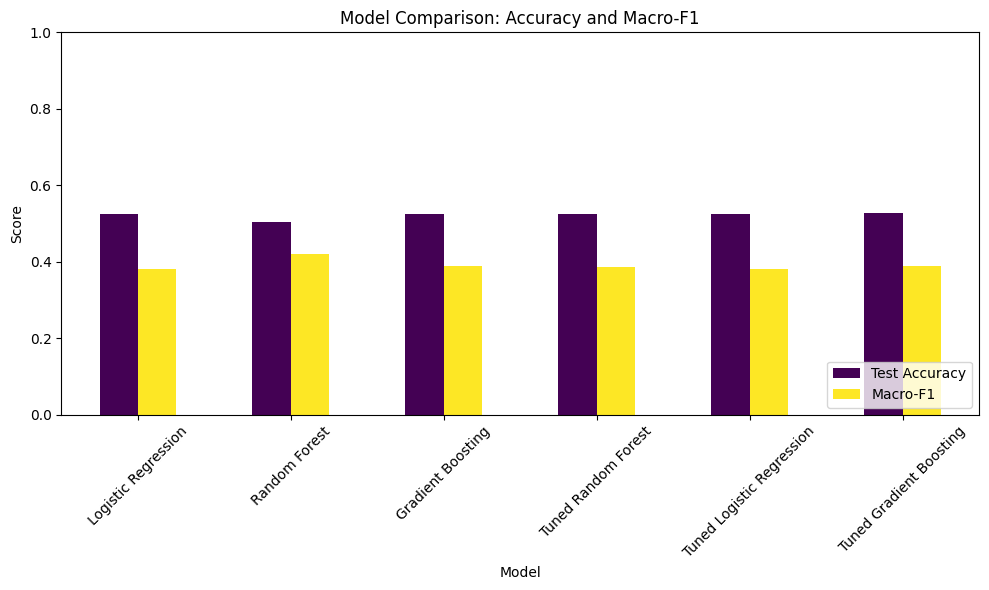

In [70]:
#model comparision
df_results[['Test Accuracy', 'Macro-F1']].plot(kind='bar', figsize=(10, 6), colormap='viridis')
plt.title('Model Comparison: Accuracy and Macro-F1')
plt.ylabel('Score')
plt.ylim(0, 1.0)
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

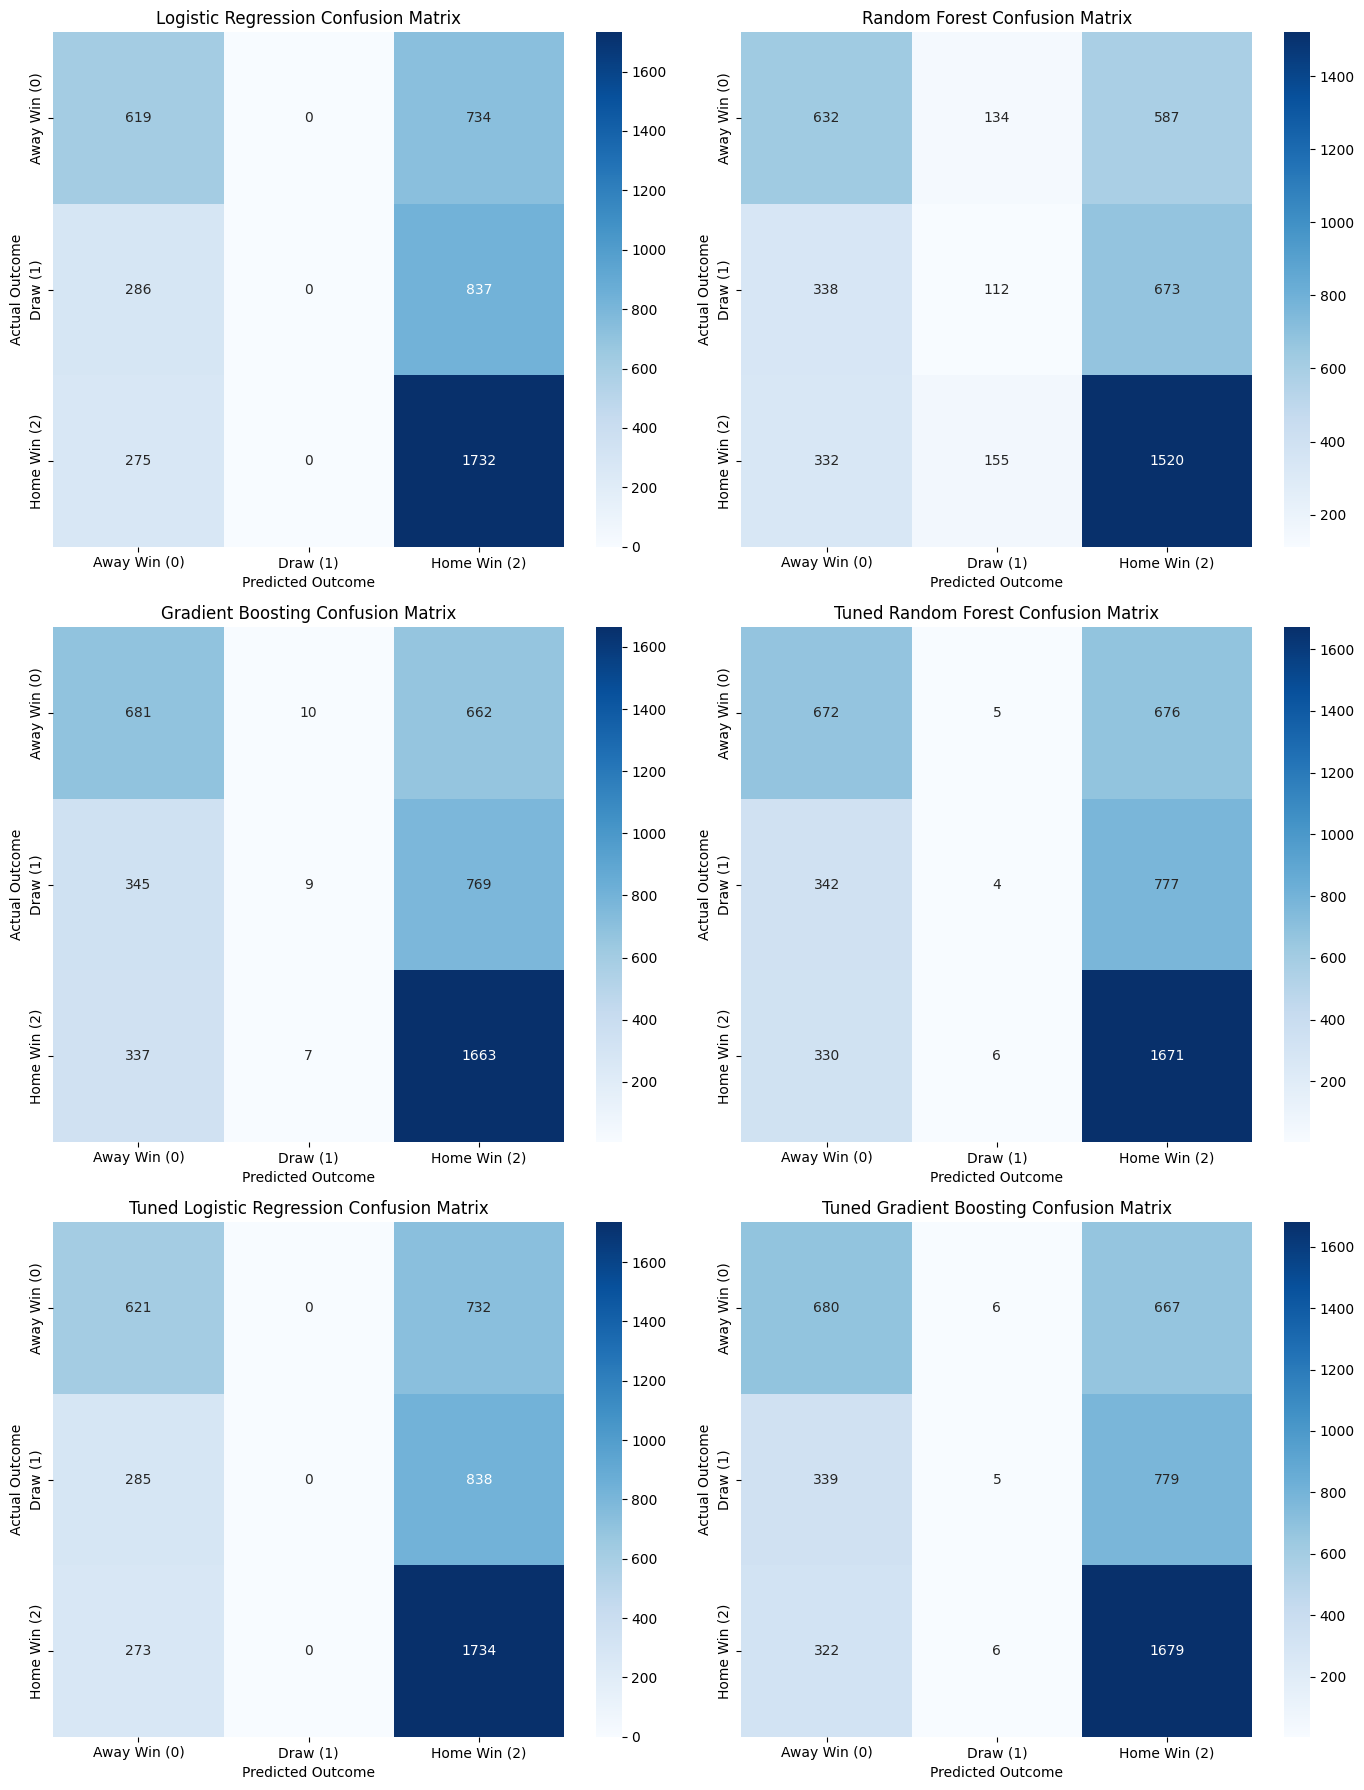

In [71]:

# Calculate dynamic grid layout depending on the number of models
num_models = len(predictions_dict)
cols = 2
rows = math.ceil(num_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(14, 6 * rows))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions_dict.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
        xticklabels=class_names, yticklabels=class_names
    )
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_xlabel('Predicted Outcome')
    axes[i].set_ylabel('Actual Outcome')

# Hide any unused axes if num_models is odd
for j in range(num_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [72]:
best_model_name = df_results['Macro-F1'].idxmax()
print(f"\n5. Best Model Selected: {best_model_name}")
print(f"Detailed Classification Report for {best_model_name}:")
print(classification_report(y_test, predictions_dict[best_model_name], target_names=class_names, zero_division=0))


5. Best Model Selected: Random Forest
Detailed Classification Report for Random Forest:
              precision    recall  f1-score   support

Away Win (0)       0.49      0.47      0.48      1353
    Draw (1)       0.28      0.10      0.15      1123
Home Win (2)       0.55      0.76      0.64      2007

    accuracy                           0.51      4483
   macro avg       0.44      0.44      0.42      4483
weighted avg       0.46      0.51      0.46      4483



In [73]:

accuracy_records = []

for name, model in trained_models.items():
    train_preds = model.predict(X_train)
    test_preds = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_preds)
    test_acc = accuracy_score(y_test, test_preds)

    accuracy_records.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc
    })

df_accuracy_summary = pd.DataFrame(accuracy_records).set_index('Model')
display(df_accuracy_summary.round(4))

,Train Accuracy,Test Accuracy
Model,,
Logistic Regression,0.5338,0.5244
Random Forest,1.0000,0.5050
Gradient Boosting,0.5457,0.5249
Tuned Random Forest,0.5847,0.5235
Tuned Logistic Regression,0.5339,0.5253
Tuned Gradient Boosting,0.5395,0.5273


### Shifting to Binary Classification: Home Win vs. Away Win Only
To simplify the modeling target,filter out all draw matches (where target = 1) and adjust target encoding to represent only binary outcomes (Away Win as '0' and Home Win as '1').

### Final SQL Extraction for Binary Classification (No Draws)
To start our binary classification pipeline from scratch, we extract only matches that ended in a home win or an away win. This filters out draw matches directly in the database query.
We also map the target directly within the SQL query:
- **`1`** representing a **Home Win** (`home_team_goal > away_team_goal`)
- **`0`** representing an **Away Win** (`home_team_goal < away_team_goal`)

In [74]:
import sqlite3
import pandas as pd

# Connect to SQLite database
db_path = '/content/drive/MyDrive/ML_Assignment/database.sqlite'
conn = sqlite3.connect(db_path)

#Extract match details for binary outcomes only (No Draws)
binary_extraction_query = """
SELECT
    m.id,
    m.date,
    m.season,
    m.stage,
    c.name AS country_name,
    l.name AS league_name,
    ht.team_long_name AS home_team,
    at.team_long_name AS away_team,
    m.home_team_goal,
    m.away_team_goal,
    -- Map Target Variable in SQL: 1 for Home Win, 0 for Away Win
    CASE
        WHEN m.home_team_goal > m.away_team_goal THEN 1
        ELSE 0
    END AS target,
    -- Pre-match Bookmaker Odds
    m.B365H,
    m.B365D,
    m.B365A
FROM
    Match m
LEFT JOIN
    Country c ON m.country_id = c.id
LEFT JOIN
    League l ON m.league_id = l.id
LEFT JOIN
    Team ht ON m.home_team_api_id = ht.team_api_id
LEFT JOIN
    Team at ON m.away_team_api_id = at.team_api_id
WHERE
    m.home_team_goal <> m.away_team_goal  -- Filter out draw matches directly
ORDER BY
    m.date ASC;
"""
players_query = """
SELECT id, date,
       home_player_1, home_player_2, home_player_3, home_player_4, home_player_5,
       home_player_6, home_player_7, home_player_8, home_player_9, home_player_10, home_player_11,
       away_player_1, away_player_2, away_player_3, away_player_4, away_player_5,
       away_player_6, away_player_7, away_player_8, away_player_9, away_player_10, away_player_11
FROM Match
ORDER BY date ASC;
"""
df_match_lineups = pd.read_sql(players_query, conn)
df_match_lineups['date'] = pd.to_datetime(df_match_lineups['date'])

# Fetch Player API IDs and ratings first to avoid NameError
player_attrs_query = """
SELECT player_api_id, date, overall_rating
FROM Player_Attributes
WHERE overall_rating IS NOT NULL
ORDER BY date ASC;
"""
df_player_attrs = pd.read_sql(player_attrs_query, conn)
df_player_attrs['date'] = pd.to_datetime(df_player_attrs['date'])

def get_recent_ratings_dict(df_player_ratings):
    # Sort ratings to easily find latest rating before match date
    return df_player_ratings.sort_values('date')
df_binary_matches = pd.read_sql(binary_extraction_query, conn)

player_ratings_sorted = get_recent_ratings_dict(df_player_attrs)
player_latest_rating = player_ratings_sorted.groupby('player_api_id').last()['overall_rating'].to_dict()

print(f"Total matches extracted: {df_binary_matches.shape[0]}")

display(df_binary_matches.head())

Total matches extracted: 19383


,id,date,season,stage,country_name,league_name,home_team,away_team,home_team_goal,away_team_goal,target,B365H,B365D,B365A
0,24559,2008-07-18 00:00:00,2008/2009,1,Switzerland,Switzerland Super League,BSC Young Boys,FC Basel,1,2,0,NaN,NaN,NaN
1,24560,2008-07-19 00:00:00,2008/2009,1,Switzerland,Switzerland Super League,FC Aarau,FC Sion,3,1,1,NaN,NaN,NaN
2,24561,2008-07-20 00:00:00,2008/2009,1,Switzerland,Switzerland Super League,FC Luzern,FC Vaduz,1,2,0,NaN,NaN,NaN
3,24562,2008-07-20 00:00:00,2008/2009,1,Switzerland,Switzerland Super League,Neuchâtel Xamax,FC Zürich,1,2,0,NaN,NaN,NaN
4,24613,2008-07-23 00:00:00,2008/2009,2,Switzerland,Switzerland Super League,FC Basel,Grasshopper Club Zürich,1,0,1,NaN,NaN,NaN


In [75]:
def get_squad_average_rating(row, prefix):
    ratings = []
    for i in range(1, 12):
        pid = row[f'{prefix}_player_{i}']
        if pd.notna(pid) and pid in player_latest_rating:
            ratings.append(player_latest_rating[pid])
    return np.mean(ratings) if len(ratings) > 0 else np.nan

df_match_lineups['home_squad_rating'] = df_match_lineups.apply(lambda r: get_squad_average_rating(r, 'home'), axis=1)
df_match_lineups['away_squad_rating'] = df_match_lineups.apply(lambda r: get_squad_average_rating(r, 'away'), axis=1)

# Construct Difference and Ratio features
df_match_lineups['squad_rating_diff'] = df_match_lineups['home_squad_rating'] - df_match_lineups['away_squad_rating']
df_match_lineups['squad_rating_ratio'] = df_match_lineups['home_squad_rating'] / df_match_lineups['away_squad_rating']


In [76]:
# Filter out draws from df_features
df_binary = df_features[df_features['target'] != 1].copy()

#Merge Squad Ratings to our Binary Dataset
df_binary_expanded = pd.merge(
    df_binary,
    df_match_lineups[['id', 'home_squad_rating', 'away_squad_rating', 'squad_rating_diff', 'squad_rating_ratio']],
    on='id',
    how='left'
)

# Drop matches where squad ratings could not be computed (e.g., historical gaps)
df_binary_expanded.dropna(subset=['squad_rating_diff'], inplace=True)
print("Expanded Binary Dataset Shape:", df_binary_expanded.shape)

Expanded Binary Dataset Shape: (16375, 21)


In [77]:

# Map target: 0 (Away Win) -> 0, 2 (Home Win) -> 1
df_binary['target'] = df_binary['target'].map({0: 0, 2: 1})

# Select features
feature_cols_bin = [
    'league_name', 'home_team', 'away_team',
    'home_form_scored', 'home_form_conceded', 'home_form_goal_diff',
    'away_form_scored', 'away_form_conceded', 'away_form_goal_diff'
]
if 'B365H' in df_binary.columns:
    feature_cols_bin.extend(['B365H', 'B365D', 'B365A'])

X_bin = df_binary[feature_cols_bin].copy()
y_bin = df_binary['target']

# Encode Categoricals
le_league_bin = LabelEncoder()
X_bin['league_name'] = le_league_bin.fit_transform(X_bin['league_name'])

le_team_bin = LabelEncoder()
all_teams_bin = pd.concat([X_bin['home_team'], X_bin['away_team']])
le_team_bin.fit(all_teams_bin)
X_bin['home_team'] = le_team_bin.transform(X_bin['home_team'])
X_bin['away_team'] = le_team_bin.transform(X_bin['away_team'])

# Train-Test Split
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_bin, y_bin, test_size=0.2, shuffle=False
)

# Feature Scaling
numeric_cols_bin = [
    'home_form_scored', 'home_form_conceded', 'home_form_goal_diff',
    'away_form_scored', 'away_form_conceded', 'away_form_goal_diff'
]
if 'B365H' in X_bin.columns:
    numeric_cols_bin.extend(['B365H', 'B365D', 'B365A'])

scaler_bin = StandardScaler()
X_train_bin[numeric_cols_bin] = scaler_bin.fit_transform(X_train_bin[numeric_cols_bin])
X_test_bin[numeric_cols_bin] = scaler_bin.transform(X_test_bin[numeric_cols_bin])

print("Binary dataset.")
print(f"New training shape: {X_train_bin.shape}, New test shape: {X_test_bin.shape}")
print("Target Class Distribution (0: Away Win, 1: Home Win):")
print(y_train_bin.value_counts(normalize=True))

Binary dataset.
New training shape: (13400, 12), New test shape: (3350, 12)
Target Class Distribution (0: Away Win, 1: Home Win):
target
1    0.619403
0    0.380597
Name: proportion, dtype: float64



EDA Analysis For 2 classes



In [78]:
# Get the original values for the training matches.
binary_eda = df_binary.loc[X_train_bin.index].copy()

# Add readable outcome labels.
binary_eda['outcome'] = binary_eda['target'].map({
    0: 'Away Win',
    1: 'Home Win'
})

outcome_order = ['Home Win', 'Away Win']


,Count,Percentage
outcome,,
Home Win,8300,61.94
Away Win,5100,38.06


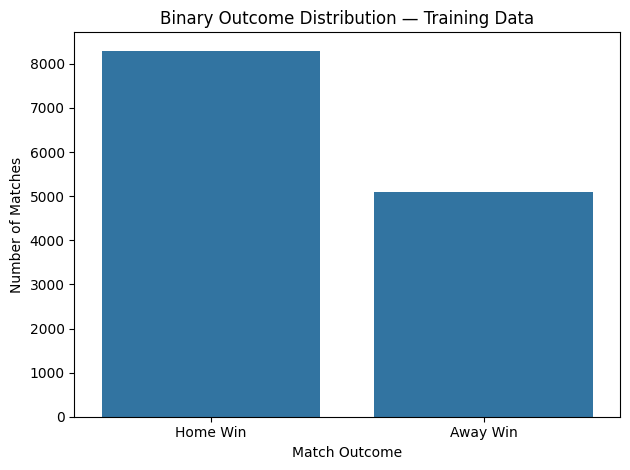

In [79]:
# Count home wins and away wins.
outcome_counts = (
    binary_eda['outcome']
    .value_counts()
    .reindex(outcome_order, fill_value=0)
)

outcome_summary = pd.DataFrame({
    'Count': outcome_counts,
    'Percentage': (
        outcome_counts / len(binary_eda) * 100
    ).round(2)
})

display(outcome_summary)

# Compare the two class sizes.
sns.countplot(
    data=binary_eda,
    x='outcome',
    order=outcome_order
)

plt.title('Binary Outcome Distribution — Training Data')
plt.xlabel('Match Outcome')
plt.ylabel('Number of Matches')
plt.tight_layout()
plt.show()

,B365H,B365D,B365A
outcome,,,
Home Win,2.066,4.028,5.889
Away Win,3.468,3.624,3.154


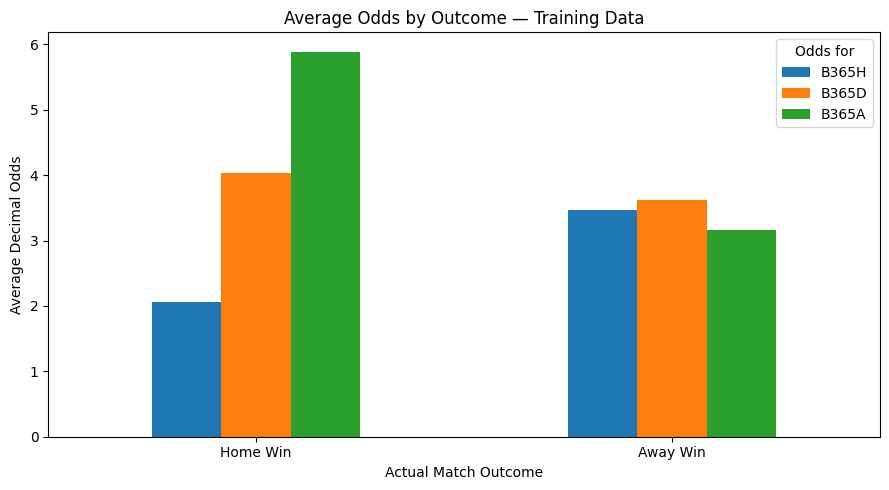

In [80]:
# Calculate average odds for each actual outcome.
odds_columns = ['B365H', 'B365D', 'B365A']

average_odds = (
    binary_eda.groupby('outcome')[odds_columns]
    .mean()
    .reindex(outcome_order)
)

display(average_odds.round(3))

# Compare the average odds.
average_odds.plot(
    kind='bar',
    figsize=(9, 5),
    rot=0
)

plt.title('Average Odds by Outcome — Training Data')
plt.xlabel('Actual Match Outcome')
plt.ylabel('Average Decimal Odds')
plt.legend(title='Odds for')
plt.tight_layout()
plt.show()

,Home Team Form,Away Team Form
outcome,,
Home Win,0.146,-0.121
Away Win,-0.263,0.302


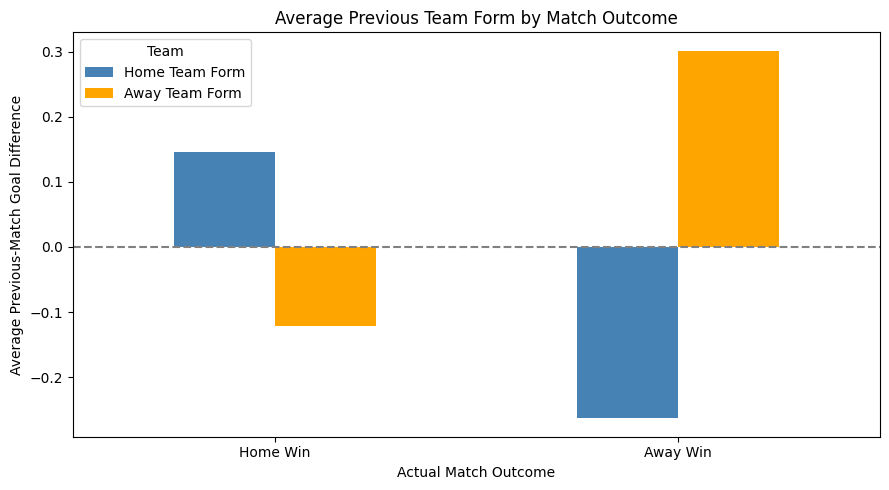

In [81]:

# Calculate average previous team form for each outcome.
form_by_outcome = (
    binary_eda.groupby('outcome')[
        ['home_form_goal_diff', 'away_form_goal_diff']
    ]
    .mean()
    .reindex(outcome_order)
)

form_by_outcome.columns = ['Home Team Form', 'Away Team Form']

display(form_by_outcome.round(3))

# Compare average previous form between outcome groups.
form_by_outcome.plot(
    kind='bar',
    figsize=(9, 5),
    rot=0,
    color=['steelblue', 'orange']
)

plt.axhline(0, color='grey', linestyle='--')
plt.title('Average Previous Team Form by Match Outcome')
plt.xlabel('Actual Match Outcome')
plt.ylabel('Average Previous-Match Goal Difference')
plt.legend(title='Team')
plt.tight_layout()
plt.show()

In [86]:

# Baseline models for binary outcomes
bin_models = {
    "Binary Logistic Regression": LogisticRegression(max_iter=1000, C=10.0, solver='liblinear', random_state=42),
    "Binary Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_split=5, random_state=42)
}

binary_evaluation_records = []

# Train and evaluate each model
for name, model in bin_models.items():
    model.fit(X_train_bin, y_train_bin)

    train_preds = model.predict(X_train_bin)
    test_preds = model.predict(X_test_bin)

    train_acc = accuracy_score(y_train_bin, train_preds)
    test_acc = accuracy_score(y_test_bin, test_preds)

    macro_f1 = f1_score(y_test_bin, test_preds, average='macro')
    recalls = recall_score(y_test_bin, test_preds, average=None, zero_division=0)

    binary_evaluation_records.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Macro-F1': macro_f1,
        'Recall (Away Win)': recalls[0],
        'Recall (Home Win)': recalls[1]
    })

xgb_bin_base = xgb.XGBClassifier(random_state=42, eval_metric='logloss')
xgb_bin_base.fit(X_train_bin, y_train_bin)

y_train_pred = xgb_bin_base.predict(X_train_bin)
y_test_pred = xgb_bin_base.predict(X_test_bin)

binary_evaluation_records.append({
    'Model': 'Binary XGBoost',
    'Train Accuracy': accuracy_score(y_train_bin, y_train_pred),
    'Test Accuracy': accuracy_score(y_test_bin, y_test_pred),
    'Macro-F1': f1_score(y_test_bin, y_test_pred, average='macro'),
    'Recall (Away Win)': recall_score(y_test_bin, y_test_pred, pos_label=0),
    'Recall (Home Win)': recall_score(y_test_bin, y_test_pred, pos_label=1)
})

df_bin_results = pd.DataFrame(binary_evaluation_records).set_index('Model')
display(df_bin_results.round(4))


,Train Accuracy,Test Accuracy,Macro-F1,Recall (Away Win),Recall (Home Win)
Model,,,,,
Binary Logistic Regression,0.7150,0.7000,0.6622,0.4533,0.8665
Binary Random Forest,0.7684,0.6991,0.6706,0.5022,0.8320
Binary XGBoost,0.8507,0.6809,0.6560,0.5111,0.7955


### Hyperparameter Tuning for Binary Classifiers
Perform hyperparameter tuning using RandomizedSearchCV on both Logistic Regression and Random Forest using our binary classification dataset

In [87]:


# Tuning Grid for Binary Logistic Regression
logreg_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

# Tuning Grid for Binary Random Forest
rf_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

print("Hyperparameter Tuning Binary Logistic Regression")
logreg_cv = RandomizedSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_distributions=logreg_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
logreg_cv.fit(X_train_bin, y_train_bin)
best_logreg_bin = logreg_cv.best_estimator_
print(f"Best Logistic Regression Params: {logreg_cv.best_params_}")

print("\nHyperparameter Tuning Binary Random Forest")
rf_cv = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=rf_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
rf_cv.fit(X_train_bin, y_train_bin)
best_rf_bin = rf_cv.best_estimator_
print(f"Best Random Forest Params: {rf_cv.best_params_}")

Hyperparameter Tuning Binary Logistic Regression
Best Logistic Regression Params: {'solver': 'liblinear', 'penalty': 'l1', 'C': 0.1}

Hyperparameter Tuning Binary Random Forest
Best Random Forest Params: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 5}


In [89]:
#  Evaluate Tuned Binary Models
tuned_bin_models = {
    "Tuned Binary Logistic Regression": best_logreg_bin,
    "Tuned Binary Random Forest": best_rf_bin,
    "Binary XGBoost": xgb_bin_base
}

final_records = []
for name, model in tuned_bin_models.items():
    train_preds = model.predict(X_train_bin)
    test_preds = model.predict(X_test_bin)

    train_acc = accuracy_score(y_train_bin, train_preds)
    test_acc = accuracy_score(y_test_bin, test_preds)
    macro_f1 = f1_score(y_test_bin, test_preds, average='macro')
    recalls = recall_score(y_test_bin, test_preds, average=None, zero_division=0)

    final_records.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Macro-F1': macro_f1,
        'Recall (Away Win)': recalls[0],
        'Recall (Home Win)': recalls[1]
    })

df_final_bin = pd.DataFrame(final_records).set_index('Model')
display(df_final_bin.round(4))

,Train Accuracy,Test Accuracy,Macro-F1,Recall (Away Win),Recall (Home Win)
Model,,,,,
Tuned Binary Logistic Regression,0.7154,0.7006,0.6633,0.4563,0.8655
Tuned Binary Random Forest,0.7193,0.7024,0.6735,0.5022,0.8375
Binary XGBoost,0.8507,0.6809,0.6560,0.5111,0.7955


### Hyperparameter Tuning for Binary XGBoost
Optimize the XGBoost parameters (learning_rate, max_depth, n_estimators, subsample, and colsample_bytree) using cross-validation.

In [90]:
# hyperparameter distribution grid for XGBoost
xgb_grid = {
    'n_estimators': [100, 150, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.15],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

print("Tuning XGBoost")
xgb_cv = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    param_distributions=xgb_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

xgb_cv.fit(X_train_bin, y_train_bin)
best_xgb_bin = xgb_cv.best_estimator_
print(f"Best XGBoost Params: {xgb_cv.best_params_}")

Tuning XGBoost
Best XGBoost Params: {'subsample': 0.9, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


In [91]:
# model comparison evaluation
tuned_bin_models['Tuned Binary XGBoost'] = best_xgb_bin

final_records_updated = []
for name, model in tuned_bin_models.items():
    train_preds = model.predict(X_train_bin)
    test_preds = model.predict(X_test_bin)

    train_acc = accuracy_score(y_train_bin, train_preds)
    test_acc = accuracy_score(y_test_bin, test_preds)
    macro_f1 = f1_score(y_test_bin, test_preds, average='macro')
    recalls = recall_score(y_test_bin, test_preds, average=None, zero_division=0)

    final_records_updated.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Macro-F1': macro_f1,
        'Recall (Away Win)': recalls[0],
        'Recall (Home Win)': recalls[1]
    })

df_final_bin_updated = pd.DataFrame(final_records_updated).set_index('Model')
display(df_final_bin_updated.round(4))

,Train Accuracy,Test Accuracy,Macro-F1,Recall (Away Win),Recall (Home Win)
Model,,,,,
Tuned Binary Logistic Regression,0.7154,0.7006,0.6633,0.4563,0.8655
Tuned Binary Random Forest,0.7193,0.7024,0.6735,0.5022,0.8375
Binary XGBoost,0.8507,0.6809,0.6560,0.5111,0.7955
Tuned Binary XGBoost,0.7169,0.7024,0.6732,0.5007,0.8385


In [92]:
feature_cols_v3 = [
    'league_name', 'home_team', 'away_team',
    'home_form_scored', 'home_form_conceded', 'home_form_goal_diff',
    'away_form_scored', 'away_form_conceded', 'away_form_goal_diff',
    'B365H', 'B365D', 'B365A',
    'home_squad_rating', 'away_squad_rating', 'squad_rating_diff', 'squad_rating_ratio'
]

X_v3 = df_binary_expanded[feature_cols_v3].copy()
y_v3 = df_binary_expanded['target']

# Encodings are already mapped; split training and testing data
X_train_v3, X_test_v3, y_train_v3, y_test_v3 = train_test_split(
    X_v3, y_v3, test_size=0.2, shuffle=False
)

# Define numeric columns including squad attributes to scale
numeric_cols_v3 = [
    'home_form_scored', 'home_form_conceded', 'home_form_goal_diff',
    'away_form_scored', 'away_form_conceded', 'away_form_goal_diff',
    'B365H', 'B365D', 'B365A',
    'home_squad_rating', 'away_squad_rating', 'squad_rating_diff', 'squad_rating_ratio'
]

scaler_v3 = StandardScaler()
X_train_v3[numeric_cols_v3] = scaler_v3.fit_transform(X_train_v3[numeric_cols_v3])
X_test_v3[numeric_cols_v3] = scaler_v3.transform(X_test_v3[numeric_cols_v3])

print(f"Train: {X_train_v3.shape}, Test: {X_test_v3.shape}")

Train: (13100, 16), Test: (3275, 16)


In [93]:
for col in ['league_name', 'home_team', 'away_team']:
    le = LabelEncoder()
    # Combine train and test to fit encoder to all possible labels safely
    le.fit(list(X_train_v3[col].astype(str)) + list(X_test_v3[col].astype(str)))
    X_train_v3[col] = le.transform(X_train_v3[col].astype(str))
    X_test_v3[col] = le.transform(X_test_v3[col].astype(str))

# Map target values: 0 (Away Win) -> 0, 2 (Home Win) -> 1 to satisfy XGBoost requirements
y_train_v3 = y_train_v3.map({0: 0, 2: 1})
y_test_v3 = y_test_v3.map({0: 0, 2: 1})

print("Training Tuned XGBoost ")
# Optimal XGBoost hyperparameters
xgb_squad = xgb.XGBClassifier(
    subsample=0.9,
    n_estimators=300,
    max_depth=3,
    learning_rate=0.01,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_squad.fit(X_train_v3, y_train_v3)

y_train_pred_v3 = xgb_squad.predict(X_train_v3)
y_test_pred_v3 = xgb_squad.predict(X_test_v3)

print(f"With Squad Ratings - Train Accuracy: {accuracy_score(y_train_v3, y_train_pred_v3):.4f}")
print(f"With Squad Ratings - Test Accuracy:  {accuracy_score(y_test_v3, y_test_pred_v3):.4f}")

print("\nExpanded Feature Set Classification Report:")
print(classification_report(y_test_v3, y_test_pred_v3, target_names=['Away Win (0)', 'Home Win (1)']))

Training Tuned XGBoost 
With Squad Ratings - Train Accuracy: 0.7300
With Squad Ratings - Test Accuracy:  0.7118

Expanded Feature Set Classification Report:
              precision    recall  f1-score   support

Away Win (0)       0.71      0.48      0.57      1316
Home Win (1)       0.71      0.86      0.78      1959

    accuracy                           0.71      3275
   macro avg       0.71      0.67      0.68      3275
weighted avg       0.71      0.71      0.70      3275



In [94]:

# Tuned Random Forest using parameters optimized
rf_squad = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42
)

print("Training final Tuned Random Forest ")
rf_squad.fit(X_train_v3, y_train_v3)

#Generate predictions on train and test sets using the Tuned Random Forest
y_train_pred_v3_rf = rf_squad.predict(X_train_v3)
y_test_pred_v3_rf = rf_squad.predict(X_test_v3)

# accuracies
rf_train_acc = accuracy_score(y_train_v3, y_train_pred_v3_rf)
rf_test_acc = accuracy_score(y_test_v3, y_test_pred_v3_rf)

print(f"Tuned Random Forest (with Squad Ratings) - Train Accuracy: {rf_train_acc:.4f}")
print(f"Tuned Random Forest (with Squad Ratings) - Test Accuracy:  {rf_test_acc:.4f}")

print("\nTuned Random Forest Feature Set Classification Report:")
print(classification_report(y_test_v3, y_test_pred_v3_rf, target_names=['Away Win (0)', 'Home Win (1)']))

Training final Tuned Random Forest 
Tuned Random Forest (with Squad Ratings) - Train Accuracy: 0.7315
Tuned Random Forest (with Squad Ratings) - Test Accuracy:  0.7145

Tuned Random Forest Feature Set Classification Report:
              precision    recall  f1-score   support

Away Win (0)       0.71      0.49      0.58      1316
Home Win (1)       0.72      0.86      0.78      1959

    accuracy                           0.71      3275
   macro avg       0.71      0.68      0.68      3275
weighted avg       0.71      0.71      0.70      3275



In [95]:

#hyperparameter grid for Logistic Regression
logreg_grid_v3 = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

print("Tuning Logistic Regression")
logreg_cv_v3 = RandomizedSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_distributions=logreg_grid_v3,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

logreg_cv_v3.fit(X_train_v3, y_train_v3)
best_logreg_v3 = logreg_cv_v3.best_estimator_
print(f"Best Logistic Regression Params: {logreg_cv_v3.best_params_}")

# Evaluate the optimized model
y_train_pred_v3_lr = best_logreg_v3.predict(X_train_v3)
y_test_pred_v3_lr = best_logreg_v3.predict(X_test_v3)

lr_train_acc = accuracy_score(y_train_v3, y_train_pred_v3_lr)
lr_test_acc = accuracy_score(y_test_v3, y_test_pred_v3_lr)

print(f"\nTuned Logistic Regression (with Squad Ratings) - Train Accuracy: {lr_train_acc:.4f}")
print(f"Tuned Logistic Regression (with Squad Ratings) - Test Accuracy:  {lr_test_acc:.4f}")

print("\nTuned Logistic Regression Feature Set Classification Metrics:")
print(classification_report(y_test_v3, y_test_pred_v3_lr, target_names=['Away Win (0)', 'Home Win (1)']))

Tuning Logistic Regression
Best Logistic Regression Params: {'solver': 'liblinear', 'penalty': 'l1', 'C': 0.01}

Tuned Logistic Regression (with Squad Ratings) - Train Accuracy: 0.7232
Tuned Logistic Regression (with Squad Ratings) - Test Accuracy:  0.7090

Tuned Logistic Regression Feature Set Classification Metrics:
              precision    recall  f1-score   support

Away Win (0)       0.70      0.49      0.57      1316
Home Win (1)       0.71      0.86      0.78      1959

    accuracy                           0.71      3275
   macro avg       0.71      0.67      0.68      3275
weighted avg       0.71      0.71      0.70      3275



### Final model metrics


,Train Accuracy,Test Accuracy,Macro-F1,Recall (Away Win),Recall (Home Win)
Model,,,,,
Hyperparameter Tuned XGBoost,0.7300,0.7118,0.6784,0.4848,0.8642
Hyperparameter Tuned Random Forest,0.7315,0.7145,0.6819,0.4909,0.8647
Hyperparameter Tuned Logistic Regression,0.7232,0.7090,0.6762,0.4863,0.8586


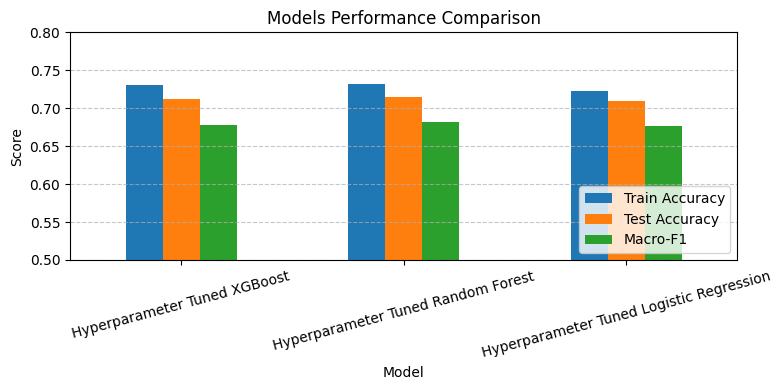

In [96]:
# Map models
v3_models = {
    'Hyperparameter Tuned XGBoost': xgb_squad,
    'Hyperparameter Tuned Random Forest': rf_squad,
    'Hyperparameter Tuned Logistic Regression': best_logreg_v3
}

v3_comparison_records = []

for name, model in v3_models.items():
    train_preds = model.predict(X_train_v3)
    test_preds = model.predict(X_test_v3)

    train_acc = accuracy_score(y_train_v3, train_preds)
    test_acc = accuracy_score(y_test_v3, test_preds)
    macro_f1 = f1_score(y_test_v3, test_preds, average='macro')
    recalls = recall_score(y_test_v3, test_preds, average=None, zero_division=0)

    v3_comparison_records.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Macro-F1': macro_f1,
        'Recall (Away Win)': recalls[0],
        'Recall (Home Win)': recalls[1]
    })

df_v3_comparison = pd.DataFrame(v3_comparison_records).set_index('Model')
display(df_v3_comparison.round(4))

# Visualize comparison
df_v3_comparison[['Train Accuracy', 'Test Accuracy', 'Macro-F1']].plot(kind='bar', figsize=(8, 4))
plt.title('Models Performance Comparison')
plt.ylabel('Score')
plt.ylim(0.5, 0.8)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()